# Supervised vs Unsupervised Embedding Analysis
Retrieval-first model comparison with cluster discovery, common issue context, and semantic graph analysis.

## Cell Labels
Each code cell includes a `Purpose:` line directly below its title.

## Extended Analysis (Recommendations)
Cells R1-R7 implement methodological improvements: lexical baselines, retrieval metrics, significance testing, error analysis, benchmarks, and distribution comparison.

In [1]:
# 01_Environment_And_Paths
# Purpose: Resolve working paths and establish project/output directories.

from pathlib import Path
import os

cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "nexustism", cwd.parent / "nexustism"]
PROJECT_ROOT = next((c for c in candidates if (c / "data_new").exists() and (c / "models").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not resolve project root with data_new/ and models/")

print("cwd:", cwd)
print("project_root:", PROJECT_ROOT)

cwd: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism
project_root: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism


In [2]:
# 01a_Core_Imports
# Purpose: Import all required libraries used by the notebook pipeline.

import gc
import json
import os
import random
import re
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.collections import LineCollection
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from scipy.stats import pearsonr, spearmanr
from sentence_transformers import InputExample, SentenceTransformer, losses
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    average_precision_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    f1_score,
    normalized_mutual_info_score,
    roc_auc_score,
    silhouette_score,
 )
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from torch.utils.data import DataLoader

In [3]:
# 01b_Runtime_Config_And_Data_Helpers
# Purpose: Define timestamp/config/seed/device/data helpers required by the pipeline.

def now_ts() -> str:
    return datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")

def find_latest_simcse_checkpoint(base_dir: Path) -> Path | None:
    if not base_dir.exists():
        return None

    run_dirs = [d for d in base_dir.iterdir() if d.is_dir() and d.name.startswith("simcse_")]
    if not run_dirs:
        run_dirs = [d for d in base_dir.iterdir() if d.is_dir()]
    if not run_dirs:
        return None

    def run_rank(path: Path) -> tuple[str, float]:
        try:
            return (path.name, float(path.stat().st_mtime))
        except Exception:
            return (path.name, 0.0)

    run_dirs = sorted(run_dirs, key=run_rank, reverse=True)
    for candidate in run_dirs:
        if (candidate / "config.json").exists() or (candidate / "modules.json").exists():
            return candidate
    return run_dirs[0]

def default_config(project_root: Path, output_root: Path) -> dict:
    return {
        "seed": 42,
        "device_policy": "auto",
        "research_mode": False,
        "paths": {
            "project_root": str(project_root),
            "output_root": str(output_root),
            "incident_csv": str(project_root / "data_new" / "incident_ticket_data_redacted.csv"),
            "test_pairs_json": str(project_root / "data_new" / "fixed_test_pairs.json"),
        },
        "eval": {
            "batch_size": 32,
            "bootstrap_iters": 200,
            "calibration_fraction": 0.3,
        },
        "simcse_train": {
            "batch_size": 64,
            "epochs": 1,
            "max_seq_length": 256,
            "lr": 2e-5,
            "warmup_ratio": 0.1,
            "max_train_sentences": 30000,
            "sweep": [
                {"batch_size": 64, "epochs": 1, "lr": 2e-5},
                {"batch_size": 128, "epochs": 1, "lr": 1e-5},
            ],
        },
        "clustering": {
            "hdbscan_min_cluster_size": 20,
            "hdbscan_min_samples": 10,
            "kmeans_k_mode": "median_hdbscan",
        },
        "graph": {
            "knn_k": 10,
            "min_edge_weight": 0.35,
        },
    }

def set_global_seed(seed: int) -> None:
    def _is_cuda_device_assert(exc: Exception) -> bool:
        return "device-side assert" in str(exc).lower()

    random.seed(seed)
    np.random.seed(seed)
    try:
        torch.manual_seed(seed)
    except Exception as exc:
        if _is_cuda_device_assert(exc):
            try:
                torch.random.default_generator.manual_seed(seed)
            except Exception:
                pass
            print("  [warn] CUDA is in an error state; restart the kernel or switch to CPU.")
            return
        raise
    if torch.cuda.is_available():
        try:
            torch.cuda.manual_seed_all(seed)
        except Exception as exc:
            if _is_cuda_device_assert(exc):
                print("  [warn] CUDA is in an error state; restart the kernel or switch to CPU.")
                return
            raise

def resolve_device(device_policy: str = "auto") -> torch.device:
    policy = str(device_policy).strip().lower()
    if policy == "cpu":
        return torch.device("cpu")
    if policy == "cuda":
        if not torch.cuda.is_available():
            raise RuntimeError("device_policy='cuda' but CUDA is not available.")
        return torch.device("cuda")
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def _first_existing(paths: list[Path]) -> Path:
    for path in paths:
        if path.exists():
            return path
    raise FileNotFoundError("None of the candidate paths exist: " + ", ".join(str(p) for p in paths))

def load_data(config: dict, project_root: Path) -> dict:
    data_path = _first_existing([
        project_root / "data_new" / "incident_ticket_data_redacted.csv",
        project_root / "data" / "incident_ticket_data_redacted.csv",
    ])
    pairs_path = _first_existing([
        project_root / "data_new" / "fixed_test_pairs.json",
        project_root / "data" / "fixed_test_pairs.json",
    ])

    incident_df = pd.read_csv(data_path)
    text_col = next((c for c in ["cleaned_text", "redacted_text", "Description", "description", "text"] if c in incident_df.columns), None)
    if text_col is None:
        raise KeyError(f"Could not find a text column in {data_path}. Columns: {incident_df.columns.tolist()}")

    corpus_texts = incident_df[text_col].dropna().astype(str).str.strip().tolist()
    corpus_texts = [t for t in corpus_texts if t]
    if not corpus_texts:
        raise ValueError(f"No usable corpus texts found in {data_path} column '{text_col}'.")

    pair_payload = json.loads(pairs_path.read_text(encoding="utf-8"))
    texts1 = [str(x) for x in pair_payload.get("texts1", [])]
    texts2 = [str(x) for x in pair_payload.get("texts2", [])]
    labels = [int(x) for x in pair_payload.get("labels", [])]

    n = len(labels)
    if not (len(texts1) == n == len(texts2)):
        raise ValueError(
            f"Pair payload length mismatch in {pairs_path}: texts1={len(texts1)}, texts2={len(texts2)}, labels={len(labels)}"
        )
    if n < 2:
        raise ValueError(f"Need at least 2 pairs for calibration/evaluation split, got {n}.")

    labels_arr = np.asarray(labels, dtype=np.int64)
    idx = np.arange(n)
    calibration_fraction = float(config.get("eval", {}).get("calibration_fraction", 0.3))
    calibration_fraction = min(0.9, max(0.1, calibration_fraction))
    stratify = labels_arr if np.unique(labels_arr).size > 1 else None

    try:
        cal_idx, eval_idx = train_test_split(
            idx,
            train_size=calibration_fraction,
            random_state=int(config.get("seed", 42)),
            stratify=stratify,
        )
    except Exception:
        split = max(1, int(n * calibration_fraction))
        cal_idx = idx[:split]
        eval_idx = idx[split:] if split < n else idx[-1:]

    def pack(indices: np.ndarray) -> dict:
        return {
            "texts1": [texts1[int(i)] for i in indices],
            "texts2": [texts2[int(i)] for i in indices],
            "labels": np.asarray([labels[int(i)] for i in indices], dtype=np.int64),
        }

    calibration_data = pack(np.asarray(cal_idx))
    evaluation_data = pack(np.asarray(eval_idx))
    if calibration_data["labels"].size == 0 or evaluation_data["labels"].size == 0:
        raise RuntimeError("Calibration/evaluation split produced an empty partition.")

    return {
        "data_path": data_path,
        "pairs_path": pairs_path,
        "corpus_texts": corpus_texts,
        "pair_labels": labels_arr,
        "calibration_data": calibration_data,
        "evaluation_data": evaluation_data,
    }

# 01b_Overrides_DataPolicy_And_RawTraining
# Purpose: Extend config/data loading to support raw training corpus with redacted artifacts.

_old_default_config = default_config

def default_config(project_root: Path, output_root: Path) -> dict:
    cfg = _old_default_config(project_root, output_root)
    cfg.setdefault("paths", {})
    cfg["paths"].setdefault("redacted_incident_csv", str(project_root / "data_new" / "incident_ticket_data_redacted.csv"))
    cfg["paths"].setdefault("raw_incident_csv", str(project_root / "data_new" / "SNow_incident_ticket_data.csv"))
    cfg.setdefault("data", {})
    cfg["data"].setdefault("training_text_source", "raw")
    cfg.setdefault("privacy", {})
    cfg["privacy"].setdefault("redact_artifacts", True)

    cfg.setdefault("eval", {})
    cfg["eval"].setdefault("retrieval_min_candidates", 6)
    cfg["eval"].setdefault("retrieval_hard_negatives", 4)
    cfg["eval"].setdefault("retrieval_random_negatives", 2)

    cfg.setdefault("simcse_train", {})
    cfg["simcse_train"].setdefault("epochs", 2)
    cfg["simcse_train"].setdefault("max_seq_length", 384)
    if not cfg["simcse_train"].get("sweep"):
        cfg["simcse_train"]["sweep"] = [
            {"batch_size": 64, "epochs": 1, "lr": 2e-5, "max_seq_length": 256},
            {"batch_size": 128, "epochs": 1, "lr": 1e-5, "max_seq_length": 256},
            {"batch_size": 64, "epochs": 2, "lr": 1e-5, "max_seq_length": 384},
        ]

    cfg.setdefault("clustering", {})
    cfg["clustering"].setdefault("reduce_method", "pca")
    cfg["clustering"].setdefault("pca_components", 50)
    cfg["clustering"].setdefault("umap_components", 20)
    return cfg


def _normalize_training_text(text: str, max_words: int = 180) -> str:
    t = str(text)
    t = re.sub(r"https?://\S+|www\.\S+", " ", t, flags=re.IGNORECASE)
    t = re.sub(r"\b(?:INC|RITM|REQ|CHG|PRB|TASK)\d+\b", " ", t, flags=re.IGNORECASE)
    t = re.sub(r"\b(?:dear|hi|hello|good morning|good afternoon|good evening)\b[^\n]{0,80}", " ", t, flags=re.IGNORECASE)
    t = re.sub(r"\b(?:thanks|thank you|regards|best regards|brgds|pls|please)\b", " ", t, flags=re.IGNORECASE)
    t = re.sub(r"[\r\n\t]+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    if not t:
        return ""
    words = t.split(" ")
    if len(words) > max_words:
        words = words[:max_words]
    return " ".join(words)


def _text_profile(texts: list[str]) -> dict:
    clean = [str(t).strip() for t in texts if str(t).strip()]
    if not clean:
        return {"count": 0, "unique": 0, "dup_ratio": 0.0, "avg_words": 0.0, "p95_words": 0.0}
    uniq = len(set(clean))
    word_lens = np.asarray([len(t.split()) for t in clean], dtype=np.float64)
    return {
        "count": int(len(clean)),
        "unique": int(uniq),
        "dup_ratio": float(1.0 - (uniq / max(1, len(clean)))),
        "avg_words": float(np.mean(word_lens)),
        "p95_words": float(np.percentile(word_lens, 95)),
    }


_old_load_data = load_data

def load_data(config: dict, project_root: Path) -> dict:
    bundle = _old_load_data(config, project_root)

    redacted_path = Path(str(config.get("paths", {}).get("redacted_incident_csv", bundle["data_path"])))
    if not redacted_path.exists():
        redacted_path = Path(str(bundle["data_path"]))
    raw_path = Path(str(config.get("paths", {}).get("raw_incident_csv", project_root / "data_new" / "SNow_incident_ticket_data.csv")))

    redacted_df = pd.read_csv(redacted_path)
    raw_df = pd.read_csv(raw_path) if raw_path.exists() else pd.DataFrame()

    redacted_text_col = next((c for c in ["cleaned_text", "redacted_text", "Description", "description", "text"] if c in redacted_df.columns), None)
    if redacted_text_col is None:
        redacted_text_col = redacted_df.columns[0]

    source_mode = str(config.get("data", {}).get("training_text_source", "raw")).strip().lower()
    train_texts: list[str]
    if source_mode == "raw" and not raw_df.empty:
        raw_col = next((c for c in ["Description", "description", "cleaned_text", "text"] if c in raw_df.columns), None)
        train_texts = raw_df[raw_col].fillna("").astype(str).tolist() if raw_col else []
    elif source_mode == "redacted":
        red_col = next((c for c in ["redacted_text", "cleaned_text", "Description", "description", "text"] if c in redacted_df.columns), redacted_text_col)
        train_texts = redacted_df[red_col].fillna("").astype(str).tolist()
    else:
        clean_col = next((c for c in ["cleaned_text", "redacted_text", "Description", "description", "text"] if c in redacted_df.columns), redacted_text_col)
        train_texts = redacted_df[clean_col].fillna("").astype(str).tolist()

    train_corpus_texts = [_normalize_training_text(t) for t in train_texts]
    train_corpus_texts = [t for t in train_corpus_texts if t]

    weak_cols = {
        "assignment_group": "Assignment group",
        "subcategory": "Subcategory",
        "service": "Service",
    }
    cluster_weak_labels = {k: ["__missing__"] * len(bundle["corpus_texts"]) for k in weak_cols.keys()}

    if "Number" in redacted_df.columns and (not raw_df.empty) and ("Number" in raw_df.columns):
        raw_map = raw_df.set_index("Number")
        red_series = redacted_df[redacted_text_col].fillna("").astype(str).str.strip()
        red_numbers = redacted_df.loc[red_series != "", "Number"].astype(str).tolist()
        red_numbers = red_numbers[: len(bundle["corpus_texts"])]
        for weak_name, raw_col in weak_cols.items():
            vals = []
            for num in red_numbers:
                v = "__missing__"
                if raw_col in raw_map.columns and num in raw_map.index:
                    hit = raw_map.loc[num, raw_col]
                    if isinstance(hit, pd.Series):
                        hit = hit.iloc[0]
                    if pd.notna(hit):
                        v = str(hit).strip() or "__missing__"
                vals.append(v)
            if len(vals) < len(bundle["corpus_texts"]):
                vals.extend(["__missing__"] * (len(bundle["corpus_texts"]) - len(vals)))
            cluster_weak_labels[weak_name] = vals

    data_profile = {
        "raw_incident": {
            "path": str(raw_path),
            "rows": int(len(raw_df)) if not raw_df.empty else 0,
            "text_profile": _text_profile(raw_df[next((c for c in ["Description", "description", "cleaned_text", "text"] if c in raw_df.columns), raw_df.columns[0] if len(raw_df.columns) else "")].fillna("").astype(str).tolist()) if (not raw_df.empty) else _text_profile([]),
        },
        "redacted_incident": {
            "path": str(redacted_path),
            "rows": int(len(redacted_df)),
            "text_profile": _text_profile(bundle["corpus_texts"]),
        },
        "training": {
            "source": source_mode,
            "text_profile": _text_profile(train_corpus_texts),
        },
        "pairs": {
            "path": str(bundle["pairs_path"]),
            "count": int(len(bundle["pair_labels"])),
            "positive_ratio": float(np.mean(np.asarray(bundle["pair_labels"]) > 0)),
        },
    }

    bundle["redacted_data_path"] = redacted_path
    bundle["raw_data_path"] = raw_path
    bundle["train_corpus_texts"] = train_corpus_texts
    bundle["training_text_source"] = source_mode
    bundle["artifact_corpus_texts"] = bundle.get("corpus_texts", [])
    bundle["cluster_weak_labels"] = cluster_weak_labels
    bundle["data_profile"] = data_profile
    return bundle


In [4]:
def build_model_registry(project_root: Path) -> list[dict]:
    latest_simcse_path = find_latest_simcse_checkpoint(project_root / "models" / "unsupervised_simcse")
    supervised_v4_path = project_root / "models" / "real_servicenow_finetuned_mpnet_lora" / "real_servicenow_v2_20260104_2321"

    # Models explicitly listed in project PDFs (Form B + Form E1).
    pdf_models = [
        {
            "name": "all-mpnet-base-v2",
            "method_type": "baseline",
            "source": "sentence-transformers",
            "path_or_id": "sentence-transformers/all-mpnet-base-v2",
            "local_only": False,
            "trust_remote_code": False,
        },
        {
            "name": "all-MiniLM-L6-v2",
            "method_type": "baseline",
            "source": "sentence-transformers",
            "path_or_id": "sentence-transformers/all-MiniLM-L6-v2",
            "local_only": False,
            "trust_remote_code": False,
        },
        {
            "name": "embeddinggemma-300m",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "google/embeddinggemma-300m",
            "local_only": False,
            "trust_remote_code": True,
        },
        {
            "name": "qwen3-embedding-8b",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "Qwen/Qwen3-Embedding-8B",
            "local_only": False,
            "trust_remote_code": True,
            "fp16": True,
        },
    ]

    # High-performing MTEB additions that are in-scope for semantic retrieval benchmarking.
    mteb_models = [
        {
            "name": "multilingual-e5-large-instruct",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "intfloat/multilingual-e5-large-instruct",
            "local_only": False,
            "trust_remote_code": False,
        },
        {
            "name": "bge-m3",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "BAAI/bge-m3",
            "local_only": False,
            "trust_remote_code": False,
        },
        {
            "name": "gte-multilingual-base",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "Alibaba-NLP/gte-multilingual-base",
            "local_only": False,
            "trust_remote_code": True,
        },
        {
            "name": "jina-embeddings-v3",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "jinaai/jina-embeddings-v3",
            "local_only": False,
            "trust_remote_code": True,
            "fp16": True,
        },
        {
            "name": "nomic-embed-text-v2-moe",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "nomic-ai/nomic-embed-text-v2-moe",
            "local_only": False,
            "trust_remote_code": True,
        },
        {
            "name": "all-MiniLM-L12-v2",
            "method_type": "baseline",
            "source": "sentence-transformers",
            "path_or_id": "sentence-transformers/all-MiniLM-L12-v2",
            "local_only": False,
            "trust_remote_code": False,
        },
        {
            "name": "qwen3-embedding-0.6b",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "Qwen/Qwen3-Embedding-0.6B",
            "local_only": False,
            "trust_remote_code": True,
        },
        {
            "name": "nv-embed-v2",
            "method_type": "baseline",
            "source": "huggingface",
            "path_or_id": "nvidia/NV-Embed-v2",
            "local_only": False,
            "trust_remote_code": True,
            "fp16": True,
        },
    ]

    local_models = [
        {
            "name": "unsupervised_simcse_latest",
            "method_type": "unsupervised",
            "source": "local",
            "path_or_id": str(latest_simcse_path) if latest_simcse_path else None,
            "local_only": True,
            "trust_remote_code": False,
        },
        {
            "name": "supervised_v4_cosine",
            "method_type": "supervised",
            "source": "local",
            "path_or_id": str(supervised_v4_path),
            "local_only": True,
            "trust_remote_code": False,
        },
    ]

    return pdf_models + mteb_models + local_models


def _is_cuda_device_assert(exc: Exception) -> bool:
    msg = str(exc).lower()
    return "device-side assert" in msg


def cleanup_memory(device: torch.device) -> None:
    gc.collect()
    if device.type == "cuda":
        try:
            torch.cuda.empty_cache()
        except Exception as exc:
            if _is_cuda_device_assert(exc):
                print("  [warn] CUDA is in an error state; restart the kernel or switch to CPU.")
                return
            raise


def _has_lora_adapter(model_path: Path) -> bool:
    return (model_path / "adapter_config.json").exists() or (model_path / "adapter_model.safetensors").exists()


def _merge_lora_into_sentence_model(model: SentenceTransformer, model_path: Path) -> SentenceTransformer:
    try:
        from peft import PeftModel
    except Exception as exc:
        raise RuntimeError("peft is required to merge LoRA adapters; install it in this environment.") from exc
    transformer = model._first_module()
    base_model = transformer.auto_model
    peft_model = PeftModel.from_pretrained(base_model, str(model_path))
    transformer.auto_model = peft_model.merge_and_unload()
    return model


def load_sentence_model(spec: dict, device: torch.device) -> SentenceTransformer:
    if spec.get("path_or_id") is None:
        raise FileNotFoundError(f"{spec['name']}: no path_or_id configured")

    kwargs = {
        "device": str(device),
        "trust_remote_code": bool(spec.get("trust_remote_code", False)),
    }
    if spec.get("local_only", False):
        kwargs["local_files_only"] = True

    # Add fp16 for large models to prevent OOM
    if spec.get("fp16", False):
        kwargs["model_kwargs"] = {"torch_dtype": torch.float16}

    def _load_sentence_transformer() -> SentenceTransformer:
        import contextlib
        import io

        capture = io.StringIO()
        with contextlib.redirect_stdout(capture):
            model = SentenceTransformer(str(spec["path_or_id"]), **kwargs)
        load_log = capture.getvalue()
        if load_log:
            unexpected_lines = [ln for ln in load_log.splitlines() if "| UNEXPECTED |" in ln]
            missing_lines = [ln for ln in load_log.splitlines() if "| MISSING" in ln]
            benign_only = (
                len(unexpected_lines) == 1
                and "embeddings.position_ids" in unexpected_lines[0]
                and not missing_lines
            )
            if not benign_only:
                print(load_log, end="" if load_log.endswith("\n") else "\n")
        return model

    try:
        model = _load_sentence_transformer()
    except (torch.cuda.OutOfMemoryError, RuntimeError) as e:
        if "out of memory" in str(e).lower() or "CUDA" in str(e):
            print(f"  OOM loading {spec['name']} in full precision, retrying with fp16...")
            cleanup_memory(device)
            kwargs["model_kwargs"] = {"torch_dtype": torch.float16}
            model = _load_sentence_transformer()
        else:
            raise

    model_path = Path(str(spec["path_or_id"]))
    if model_path.exists() and _has_lora_adapter(model_path):
        model = _merge_lora_into_sentence_model(model, model_path)
    return model


def build_reload_spec(model_name: str, payload: dict, model_registry: list[dict] | None = None) -> dict:
    registry = model_registry
    if registry is None:
        registry = globals().get("MODEL_REGISTRY", [])
    reg = next((s for s in registry if s.get("name") == model_name), None)

    local_only = payload.get("source") in ("local", "local_or_trained")
    trust_remote_code = bool(payload.get("trust_remote_code", False))
    fp16 = bool(payload.get("fp16", False))
    method_type = payload.get("method_type")
    if reg:
        local_only = bool(reg.get("local_only", local_only))
        trust_remote_code = bool(reg.get("trust_remote_code", trust_remote_code))
        fp16 = bool(reg.get("fp16", fp16))
        method_type = reg.get("method_type", method_type)

    return {
        "name": model_name,
        "method_type": method_type,
        "path_or_id": payload.get("path_or_id"),
        "local_only": local_only,
        "trust_remote_code": trust_remote_code,
        "fp16": fp16,
    }


In [5]:
# 01c_Evaluation_And_Training_Helpers
# Purpose: Define retrieval metrics, bootstrap logic, model evaluation, and SimCSE training utilities.

def cosine_scores(model: SentenceTransformer, texts1: list[str], texts2: list[str], batch_size: int) -> np.ndarray:
    def encode_with_retry(texts: list[str], start_batch_size: int) -> np.ndarray:
        bs = int(start_batch_size)
        while True:
            try:
                return model.encode(texts, batch_size=bs, convert_to_numpy=True, show_progress_bar=False)
            except (torch.cuda.OutOfMemoryError, RuntimeError) as exc:
                if "out of memory" not in str(exc).lower():
                    raise
                if bs <= 1:
                    raise
                bs = max(1, bs // 2)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                print(f"  [warn] OOM during encode; retrying with batch_size={bs}")

    # Encode in two passes to keep peak GPU memory lower for large models.
    emb1 = encode_with_retry(texts1, batch_size)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    emb2 = encode_with_retry(texts2, batch_size)
    emb1 = normalize(np.asarray(emb1, dtype=np.float32), norm="l2")
    emb2 = normalize(np.asarray(emb2, dtype=np.float32), norm="l2")
    scores = np.sum(emb1 * emb2, axis=1)
    return scores.astype(np.float64)

def bootstrap_ci(metric_fn, labels: np.ndarray, scores: np.ndarray, iters: int, seed: int) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    values = []
    n = labels.shape[0]
    for _ in range(iters):
        idx = rng.integers(0, n, size=n)
        y = labels[idx]
        s = scores[idx]
        try:
            values.append(float(metric_fn(y, s)))
        except Exception:
            continue
    if not values:
        return (float("nan"), float("nan"))
    values = np.asarray(values, dtype=np.float64)
    return (float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5)))

def calibrate_threshold(labels: np.ndarray, scores: np.ndarray) -> tuple[float, float]:
    best_thr = 0.0
    best_f1 = -1.0
    for thr in np.linspace(-1.0, 1.0, 401):
        preds = (scores >= thr).astype(int)
        f1 = f1_score(labels, preds)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_thr = float(thr)
    return best_thr, best_f1

def retrieval_metrics(labels: np.ndarray, scores: np.ndarray, threshold: float, bootstrap_iters: int, seed: int) -> dict:
    preds = (scores >= threshold).astype(int)
    roc_auc = float(roc_auc_score(labels, scores))
    pr_auc = float(average_precision_score(labels, scores))
    spearman = float(spearmanr(scores, labels)[0])
    pearson = float(pearsonr(scores, labels)[0])
    f1 = float(f1_score(labels, preds))
    acc = float(accuracy_score(labels, preds))
    spearman_ci = bootstrap_ci(lambda y, s: spearmanr(s, y)[0], labels, scores, bootstrap_iters, seed)
    roc_auc_ci = bootstrap_ci(roc_auc_score, labels, scores, bootstrap_iters, seed)
    return {
        "spearman": spearman,
        "pearson": pearson,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "f1": f1,
        "accuracy": acc,
        "threshold": float(threshold),
        "spearman_ci": [float(spearman_ci[0]), float(spearman_ci[1])],
        "roc_auc_ci": [float(roc_auc_ci[0]), float(roc_auc_ci[1])],
        "mean_similarity": float(np.mean(scores)),
        "std_similarity": float(np.std(scores)),
    }

def evaluate_model_pairs(model: SentenceTransformer, calibration: dict, evaluation: dict, config: dict) -> dict:
    batch_size = config["eval"]["batch_size"]
    cal_scores = cosine_scores(model, calibration["texts1"], calibration["texts2"], batch_size)
    eval_scores = cosine_scores(model, evaluation["texts1"], evaluation["texts2"], batch_size)

    threshold, best_cal_f1 = calibrate_threshold(calibration["labels"], cal_scores)
    cal_metrics = retrieval_metrics(
        calibration["labels"],
        cal_scores,
        threshold,
        config["eval"]["bootstrap_iters"],
        config["seed"],
    )
    cal_metrics["best_calibration_f1"] = float(best_cal_f1)
    eval_metrics = retrieval_metrics(
        evaluation["labels"],
        eval_scores,
        threshold,
        config["eval"]["bootstrap_iters"],
        config["seed"],
    )
    return {"calibration": cal_metrics, "evaluation": eval_metrics}


def run_model_evaluation(
    spec: dict,
    device: torch.device,
    calibration_data: dict,
    evaluation_data: dict,
    config: dict,
    model_metrics: dict,
    loaded_models: dict,
    failed_models: dict,
    alias: str | None = None,
) -> dict | None:
    model_name = alias or spec["name"]
    print(f"\nEvaluating model: {model_name}")
    try:
        start_ts = time.perf_counter()
        print(
            "  load_config:",
            {
                "path_or_id": str(spec.get("path_or_id")),
                "local_only": bool(spec.get("local_only", False)),
                "trust_remote_code": bool(spec.get("trust_remote_code", False)),
                "device": str(device),
            },
        )
        model = load_sentence_model(spec, device)
        print(f"  model loaded in {time.perf_counter() - start_ts:.1f}s")
        metrics = evaluate_model_pairs(model, calibration_data, evaluation_data, config)
        model_metrics[model_name] = {
            "model_name": model_name,
            "method_type": spec["method_type"],
            "source": spec["source"],
            "path_or_id": str(spec["path_or_id"]),
            "metrics": metrics,
        }
        loaded_models[model_name] = model
        print(
            f"{model_name} eval -> Spearman={metrics['evaluation']['spearman']:.4f}, "
            f"ROC-AUC={metrics['evaluation']['roc_auc']:.4f}, F1={metrics['evaluation']['f1']:.4f}"
        )
        print(f"  total_eval_time_s={time.perf_counter() - start_ts:.1f}")
        return model_metrics[model_name]
    except Exception as exc:
        failed_models[model_name] = str(exc)
        print(f"Skipping {model_name}: {exc}")
        if device.type == "cuda" and _is_cuda_device_assert(exc):
            print("  [warn] CUDA device-side assert triggered; restart the kernel or rerun on CPU.")
            return None
        cleanup_memory(device)
        return None

def train_simcse_candidate(
    sweep_cfg: dict,
    config: dict,
    device: torch.device,
    output_root: Path,
    corpus_texts: list[str],
    calibration_data: dict,
    evaluation_data: dict,
) -> tuple[Path, dict]:
    params = dict(config["simcse_train"])
    params.update(sweep_cfg)
    run_tag = f"run_{int(time.time())}_{params['batch_size']}_{params['epochs']}"
    out_dir = output_root / "simcse_sweep" / run_tag
    out_dir.parent.mkdir(parents=True, exist_ok=True)

    model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2", device=str(device), trust_remote_code=False)
    model.max_seq_length = int(params["max_seq_length"])
    max_train = int(params.get("max_train_sentences", 30000))
    train_subset = corpus_texts[:max_train]
    train_examples = [InputExample(texts=[t, t]) for t in train_subset]
    train_loader = DataLoader(
        train_examples,
        batch_size=int(params["batch_size"]),
        shuffle=True,
        drop_last=True,
    )
    train_loss = losses.MultipleNegativesRankingLoss(model)
    total_steps = max(1, len(train_loader) * int(params["epochs"]))
    warmup_steps = int(total_steps * float(params["warmup_ratio"]))
    model.fit(
        train_objectives=[(train_loader, train_loss)],
        epochs=int(params["epochs"]),
        warmup_steps=warmup_steps,
        optimizer_params={"lr": float(params["lr"])},
        output_path=str(out_dir),
        show_progress_bar=False,
        use_amp=(device.type == "cuda"),
    )

    eval_model = SentenceTransformer(str(out_dir), device=str(device), local_files_only=True, trust_remote_code=False)
    candidate_metrics = evaluate_model_pairs(eval_model, calibration_data, evaluation_data, config)
    del model
    del eval_model
    cleanup_memory(device)
    return out_dir, candidate_metrics


In [6]:
# 01d_Retrieval_Embedding_And_Clustering_Helpers
# Purpose: Define helpers for retrieval ranking, corpus embedding generation, and clustering execution.

def build_retrieval_table(model_metrics: dict) -> tuple[pd.DataFrame, dict, dict]:
    rows = []
    for model_name, payload in model_metrics.items():
        m = payload["metrics"]["evaluation"]
        rows.append(
            {
                "model_name": model_name,
                "method_type": payload["method_type"],
                "source": payload["source"],
                "path_or_id": payload["path_or_id"],
                "spearman": m["spearman"],
                "pearson": m["pearson"],
                "roc_auc": m["roc_auc"],
                "pr_auc": m["pr_auc"],
                "f1": m["f1"],
                "accuracy": m["accuracy"],
                "threshold": m["threshold"],
                "spearman_ci_low": m["spearman_ci"][0],
                "spearman_ci_high": m["spearman_ci"][1],
                "roc_auc_ci_low": m["roc_auc_ci"][0],
                "roc_auc_ci_high": m["roc_auc_ci"][1],
            }
        )

    retrieval_df = pd.DataFrame(rows)
    retrieval_df = retrieval_df.sort_values(["spearman", "roc_auc", "f1"], ascending=[False, False, False]).reset_index(drop=True)
    method_summary = {}
    for method_name, group in retrieval_df.groupby("method_type"):
        best_row = group.sort_values(["spearman", "roc_auc", "f1"], ascending=[False, False, False]).iloc[0]
        method_summary[method_name] = {
            "best_model": str(best_row["model_name"]),
            "best_spearman": float(best_row["spearman"]),
            "best_roc_auc": float(best_row["roc_auc"]),
            "best_f1": float(best_row["f1"]),
            "median_spearman": float(group["spearman"].median()),
            "median_roc_auc": float(group["roc_auc"].median()),
            "median_f1": float(group["f1"].median()),
        }
    winner = retrieval_df.iloc[0].to_dict()
    return retrieval_df, method_summary, winner

def encode_corpus(
    retrieval_df: pd.DataFrame,
    model_metrics: dict,
    loaded_models: dict,
    device: torch.device,
    corpus_texts: list[str],
    batch_size: int,
) -> dict[str, np.ndarray]:
    embeddings = {}
    cpu_fallback = False
    for _, row in retrieval_df.iterrows():
        model_name = row["model_name"]
        model = loaded_models.get(model_name)
        payload = model_metrics.get(model_name)
        if payload is None:
            print(f"[warn] Missing metrics for {model_name}; skipping full-corpus encoding.")
            continue

        device_for_load = torch.device("cpu") if cpu_fallback else device
        try:
            if model is None:
                spec = build_reload_spec(model_name, payload)
                model = load_sentence_model(spec, device_for_load)
            emb = model.encode(
                corpus_texts,
                batch_size=batch_size,
                convert_to_numpy=True,
                show_progress_bar=True,
            )
            embeddings[model_name] = normalize(np.asarray(emb, dtype=np.float32), norm="l2")
        except Exception as exc:
            if device_for_load.type == "cuda" and _is_cuda_device_assert(exc):
                print(f"  [warn] CUDA assert during {model_name} encode; switching remaining models to CPU.")
                cpu_fallback = True
                model = None
                cleanup_memory(device)
                try:
                    spec = build_reload_spec(model_name, payload)
                    model = load_sentence_model(spec, torch.device("cpu"))
                    emb = model.encode(
                        corpus_texts,
                        batch_size=batch_size,
                        convert_to_numpy=True,
                        show_progress_bar=True,
                    )
                    embeddings[model_name] = normalize(np.asarray(emb, dtype=np.float32), norm="l2")
                except Exception as cpu_exc:
                    print(f"[warn] CPU fallback failed for {model_name}: {cpu_exc}")
            else:
                print(f"[warn] Skipping {model_name} during full-corpus encoding: {exc}")
        finally:
            if model_name in loaded_models:
                del loaded_models[model_name]
            if model is not None:
                del model
            cleanup_memory(device_for_load)

    return embeddings


def run_hdbscan(embeddings: dict[str, np.ndarray], config: dict) -> tuple[dict, dict, list[int]]:
    cluster_results = {name: {} for name in embeddings.keys()}
    cluster_labels = {name: {} for name in embeddings.keys()}
    discovered_k = []
    try:
        import hdbscan

        hdbscan_available = True
    except Exception as exc:
        hdbscan_available = False
        hdbscan_error = str(exc)

    for model_name, emb in embeddings.items():
        if not hdbscan_available:
            cluster_results[model_name]["hdbscan"] = {"available": False, "reason": hdbscan_error}
            cluster_labels[model_name]["hdbscan"] = None
            continue

        clusterer = hdbscan.HDBSCAN(
            min_cluster_size=int(config["clustering"]["hdbscan_min_cluster_size"]),
            min_samples=int(config["clustering"]["hdbscan_min_samples"]),
            cluster_selection_method="eom",
        )
        labels = clusterer.fit_predict(emb)
        cluster_labels[model_name]["hdbscan"] = labels
        n_clusters = int(len(set(labels)) - (1 if -1 in labels else 0))
        noise_ratio = float(np.mean(labels == -1)) if labels.size else 0.0

        payload = {
            "available": True,
            "n_clusters": n_clusters,
            "noise_ratio": noise_ratio,
            "silhouette": float("nan"),
            "calinski_harabasz": float("nan"),
            "davies_bouldin": float("nan"),
        }
        non_noise = labels != -1
        if n_clusters > 1 and np.sum(non_noise) > n_clusters:
            emb_nn = emb[non_noise]
            labels_nn = labels[non_noise]
            payload["silhouette"] = float(silhouette_score(emb_nn, labels_nn))
            payload["calinski_harabasz"] = float(calinski_harabasz_score(emb_nn, labels_nn))
            payload["davies_bouldin"] = float(davies_bouldin_score(emb_nn, labels_nn))
        cluster_results[model_name]["hdbscan"] = payload
        if n_clusters > 1:
            discovered_k.append(n_clusters)
    return cluster_results, cluster_labels, discovered_k


def run_kmeans(
    embeddings: dict[str, np.ndarray],
    cluster_results: dict,
    cluster_labels: dict,
    discovered_k: list[int],
    config: dict,
) -> tuple[dict, dict, int]:
    if config["clustering"]["kmeans_k_mode"] == "median_hdbscan" and discovered_k:
        derived_k = int(round(float(np.median(discovered_k))))
    else:
        derived_k = 10
    global_k = max(2, min(50, derived_k))
    centroids = {}
    for model_name, emb in embeddings.items():
        km = KMeans(n_clusters=global_k, random_state=config["seed"], n_init=10)
        labels = km.fit_predict(emb)
        cluster_labels[model_name]["kmeans"] = labels
        centroids[model_name] = km.cluster_centers_
        cluster_results[model_name]["kmeans"] = {
            "n_clusters": int(global_k),
            "noise_ratio": 0.0,
            "silhouette": float(silhouette_score(emb, labels)),
            "calinski_harabasz": float(calinski_harabasz_score(emb, labels)),
            "davies_bouldin": float(davies_bouldin_score(emb, labels)),
        }
    return cluster_results, centroids, global_k

# 01d_Overrides_ReducedSpaceClustering
# Purpose: Cluster on reduced embedding spaces (PCA/UMAP fallback) for more stable partitions.

def _reduce_embeddings_for_clustering(emb: np.ndarray, config: dict) -> tuple[np.ndarray, dict]:
    method = str(config.get("clustering", {}).get("reduce_method", "pca")).lower()
    n_samples, n_dims = emb.shape
    if n_samples < 3:
        return emb, {"method": "none", "components": int(n_dims), "reason": "too_few_samples"}

    if method == "umap":
        try:
            import umap
            n_comp = int(config.get("clustering", {}).get("umap_components", 20))
            n_comp = max(2, min(n_comp, n_samples - 1, n_dims))
            reducer = umap.UMAP(n_components=n_comp, random_state=int(config.get("seed", 42)))
            return reducer.fit_transform(emb), {"method": "umap", "components": int(n_comp)}
        except Exception as exc:
            print(f"[warn] UMAP unavailable/failing; fallback to PCA: {exc}")

    n_comp = int(config.get("clustering", {}).get("pca_components", 50))
    n_comp = max(2, min(n_comp, n_samples - 1, n_dims))
    return PCA(n_components=n_comp, random_state=int(config.get("seed", 42))).fit_transform(emb), {"method": "pca", "components": int(n_comp)}


_old_run_hdbscan = run_hdbscan
_old_run_kmeans = run_kmeans

def run_hdbscan(embeddings: dict[str, np.ndarray], config: dict) -> tuple[dict, dict, list[int]]:
    cluster_results = {name: {} for name in embeddings.keys()}
    cluster_labels = {name: {} for name in embeddings.keys()}
    discovered_k = []
    try:
        import hdbscan
        hdbscan_available = True
    except Exception as exc:
        hdbscan_available = False
        hdbscan_error = str(exc)

    for model_name, emb in embeddings.items():
        emb_cluster, reduction_meta = _reduce_embeddings_for_clustering(emb, config)
        if not hdbscan_available:
            cluster_results[model_name]["hdbscan"] = {
                "available": False,
                "reason": hdbscan_error,
                "embedding_reduction": reduction_meta,
            }
            cluster_labels[model_name]["hdbscan"] = None
            continue

        clusterer = hdbscan.HDBSCAN(
            min_cluster_size=int(config["clustering"]["hdbscan_min_cluster_size"]),
            min_samples=int(config["clustering"]["hdbscan_min_samples"]),
            cluster_selection_method="eom",
        )
        labels = clusterer.fit_predict(emb_cluster)
        cluster_labels[model_name]["hdbscan"] = labels
        n_clusters = int(len(set(labels)) - (1 if -1 in labels else 0))
        noise_ratio = float(np.mean(labels == -1)) if labels.size else 0.0

        payload = {
            "available": True,
            "n_clusters": n_clusters,
            "noise_ratio": noise_ratio,
            "silhouette": float("nan"),
            "calinski_harabasz": float("nan"),
            "davies_bouldin": float("nan"),
            "embedding_reduction": reduction_meta,
        }
        non_noise = labels != -1
        if n_clusters > 1 and np.sum(non_noise) > n_clusters:
            emb_nn = emb_cluster[non_noise]
            labels_nn = labels[non_noise]
            payload["silhouette"] = float(silhouette_score(emb_nn, labels_nn))
            payload["calinski_harabasz"] = float(calinski_harabasz_score(emb_nn, labels_nn))
            payload["davies_bouldin"] = float(davies_bouldin_score(emb_nn, labels_nn))
        cluster_results[model_name]["hdbscan"] = payload
        if n_clusters > 1:
            discovered_k.append(n_clusters)
    return cluster_results, cluster_labels, discovered_k


def run_kmeans(
    embeddings: dict[str, np.ndarray],
    cluster_results: dict,
    cluster_labels: dict,
    discovered_k: list[int],
    config: dict,
) -> tuple[dict, dict, int]:
    if config["clustering"]["kmeans_k_mode"] == "median_hdbscan" and discovered_k:
        derived_k = int(round(float(np.median(discovered_k))))
    else:
        derived_k = 10
    global_k = max(2, min(50, derived_k))
    centroids = {}
    for model_name, emb in embeddings.items():
        emb_cluster, reduction_meta = _reduce_embeddings_for_clustering(emb, config)
        km = KMeans(n_clusters=global_k, random_state=config["seed"], n_init=10)
        labels = km.fit_predict(emb_cluster)
        cluster_labels[model_name]["kmeans"] = labels
        centroids[model_name] = km.cluster_centers_
        cluster_results[model_name]["kmeans"] = {
            "n_clusters": int(global_k),
            "noise_ratio": 0.0,
            "silhouette": float(silhouette_score(emb_cluster, labels)),
            "calinski_harabasz": float(calinski_harabasz_score(emb_cluster, labels)),
            "davies_bouldin": float(davies_bouldin_score(emb_cluster, labels)),
            "embedding_reduction": reduction_meta,
        }
    return cluster_results, centroids, global_k


In [7]:
# 01e_Cluster_Context_And_Graph_Helpers
# Purpose: Define helpers for cluster interpretation, semantic graph generation, and method summarization.

def build_cluster_context(
    embeddings: dict[str, np.ndarray],
    cluster_labels: dict,
    centroids: dict,
    corpus_texts: list[str],
    output_root: Path,
) -> pd.DataFrame:
    rows = []

    def top_terms(texts: list[str], top_n: int = 5) -> list[str]:
        if len(texts) < 2:
            return []
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words="english", max_features=5000)
        mat = vectorizer.fit_transform(texts)
        if mat.shape[1] == 0:
            return []
        scores = np.asarray(mat.sum(axis=0)).ravel()
        terms = np.asarray(vectorizer.get_feature_names_out())
        order = np.argsort(scores)[::-1][:top_n]
        return terms[order].tolist()

    def representative_texts(emb: np.ndarray, indices: np.ndarray, centroid: np.ndarray | None) -> tuple[str, str]:
        if indices.size == 0:
            return ("", "")
        subset = emb[indices]

        # KMeans may run in reduced space (e.g., PCA/UMAP), so centroid can have different dimensionality.
        # If dimensions do not match the embedding space used here, fall back to the subset mean.
        if centroid is None:
            ref = subset.mean(axis=0)
        else:
            c = np.asarray(centroid).ravel()
            ref = c if c.shape[0] == subset.shape[1] else subset.mean(axis=0)

        dists = np.linalg.norm(subset - ref, axis=1)
        order = np.argsort(dists)
        first = corpus_texts[int(indices[order[0]])]
        second = first if order.size == 1 else corpus_texts[int(indices[order[1]])]
        return first, second

    for model_name, emb in embeddings.items():
        for algo in ["kmeans", "hdbscan"]:
            labels = cluster_labels[model_name].get(algo)
            if labels is None:
                continue
            for cluster_id in [c for c in np.unique(labels) if c != -1]:
                idx = np.where(labels == cluster_id)[0]
                cluster_texts = [corpus_texts[int(i)] for i in idx]
                centroid = None
                if algo == "kmeans":
                    centroid = centroids[model_name][int(cluster_id)]
                rep1, rep2 = representative_texts(emb, idx, centroid)
                rows.append(
                    {
                        "model_name": model_name,
                        "cluster_algo": algo,
                        "cluster_id": int(cluster_id),
                        "cluster_size": int(idx.size),
                        "top_terms": " | ".join(top_terms(cluster_texts, top_n=5)),
                        "representative_text_1": rep1,
                        "representative_text_2": rep2,
                    }
                )

    report_df = pd.DataFrame(rows)
    if report_df.empty:
        raise RuntimeError("Cluster report is empty; clustering did not produce usable labels.")
    report_df = report_df.sort_values(["model_name", "cluster_algo", "cluster_size"], ascending=[True, True, False])
    report_df.to_csv(output_root / "cluster_report.csv", index=False)
    report_df.to_json(output_root / "cluster_report.json", orient="records", indent=2)
    return report_df

def build_semantic_graphs(
    embeddings: dict[str, np.ndarray],
    cluster_labels: dict,
    config: dict,
    output_root: Path,
) -> dict:
    graph_summary = {}
    for model_name, emb in embeddings.items():
        n_nodes = emb.shape[0]
        n_neighbors = min(int(config["graph"]["knn_k"]) + 1, n_nodes)
        nbrs = NearestNeighbors(n_neighbors=n_neighbors, metric="cosine")
        nbrs.fit(emb)
        distances, indices = nbrs.kneighbors(emb)

        min_weight = float(config["graph"]["min_edge_weight"])
        edge_map = {}
        for i in range(n_nodes):
            for j_pos in range(1, indices.shape[1]):
                j = int(indices[i, j_pos])
                if i == j:
                    continue
                w = float(1.0 - distances[i, j_pos])
                if w < min_weight:
                    continue
                a, b = (i, j) if i < j else (j, i)
                if (a, b) not in edge_map or w > edge_map[(a, b)]:
                    edge_map[(a, b)] = w

        edges = list(edge_map.items())
        if edges:
            rows = []
            cols = []
            data = []
            for (a, b), w in edges:
                rows.extend([a, b])
                cols.extend([b, a])
                data.extend([w, w])
            adj = sparse.coo_matrix((data, (rows, cols)), shape=(n_nodes, n_nodes))
            n_components, _ = connected_components(adj, directed=False, return_labels=True)
        else:
            n_components = n_nodes

        avg_degree = float((2 * len(edges)) / max(1, n_nodes))
        coords = PCA(n_components=2, random_state=config["seed"]).fit_transform(emb)
        labels = cluster_labels[model_name].get("kmeans")
        if labels is None:
            labels = np.zeros(n_nodes, dtype=int)

        fig, ax = plt.subplots(figsize=(10, 8))
        if edges:
            segments = [[coords[a].tolist(), coords[b].tolist()] for (a, b), _ in edges]
            lc = LineCollection(segments, colors="lightgray", linewidths=0.2, alpha=0.12)
            ax.add_collection(lc)
        ax.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="tab20", s=8, alpha=0.8, linewidths=0)
        ax.set_title(f"Semantic kNN Graph - {model_name}")
        ax.set_xlabel("PCA-1")
        ax.set_ylabel("PCA-2")
        ax.grid(alpha=0.2)
        out = output_root / f"semantic_graph_{model_name}.png"
        plt.tight_layout()
        plt.savefig(out, dpi=180, bbox_inches="tight")
        plt.close(fig)

        graph_summary[model_name] = {
            "nodes": int(n_nodes),
            "edges": int(len(edges)),
            "avg_degree": avg_degree,
            "n_components": int(n_components),
            "min_edge_weight": min_weight,
            "graph_path": str(out),
        }
    return graph_summary

def summarize_methods(retrieval_df: pd.DataFrame, cluster_results: dict) -> tuple[dict, dict]:
    method_cluster_summary = {}
    for method_name in sorted(retrieval_df["method_type"].unique().tolist()):
        names = retrieval_df.loc[retrieval_df["method_type"] == method_name, "model_name"].tolist()
        kmeans_sil = [cluster_results[n]["kmeans"]["silhouette"] for n in names if "kmeans" in cluster_results.get(n, {})]
        method_cluster_summary[method_name] = {
            "median_kmeans_silhouette": float(np.median(kmeans_sil)) if kmeans_sil else float("nan"),
            "best_kmeans_silhouette": float(np.max(kmeans_sil)) if kmeans_sil else float("nan"),
        }
    winner_row = retrieval_df.iloc[0]
    winner = {
        "winner_model": str(winner_row["model_name"]),
        "winner_method_type": str(winner_row["method_type"]),
        "decision_rule": "retrieval_first_spearman_then_roc_auc_then_f1",
        "retrieval_metrics": {
            "spearman": float(winner_row["spearman"]),
            "roc_auc": float(winner_row["roc_auc"]),
            "pr_auc": float(winner_row["pr_auc"]),
            "f1": float(winner_row["f1"]),
        },
        "cluster_evidence": method_cluster_summary,
    }
    return method_cluster_summary, winner

In [8]:
# 01f_Save_Helpers
# Purpose: Define serialization and artifact-saving helpers for metrics and summaries.

def to_native(value):
    if isinstance(value, dict):
        return {str(k): to_native(v) for k, v in value.items()}
    if isinstance(value, list):
        return [to_native(v) for v in value]
    if isinstance(value, tuple):
        return [to_native(v) for v in value]
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    return value

def save_artifacts(
    output_root: Path,
    run_timestamp: str,
    project_root: Path,
    device: torch.device,
    config: dict,
    data_bundle: dict,
    failed_models: dict,
    model_metrics: dict,
    method_summary: dict,
    method_cluster_summary: dict,
    global_k: int,
    discovered_k: list[int],
    cluster_results: dict,
    graph_summary: dict,
    winner: dict,
    retrieval_df: pd.DataFrame,
    simcse_sweep_results: list[dict] | None = None,
) -> dict:
    payload = {
        "run_metadata": {
            "timestamp": run_timestamp,
            "project_root": str(project_root),
            "output_root": str(output_root),
            "device": str(device),
            "seed": int(config["seed"]),
            "research_mode": bool(config["research_mode"]),
            "data_path": str(data_bundle["data_path"]),
            "test_pairs_path": str(data_bundle["pairs_path"]),
            "corpus_text_count": int(len(data_bundle["corpus_texts"])),
            "pair_count": int(len(data_bundle["pair_labels"])),
            "failed_models": failed_models,
            "simcse_sweep_results": simcse_sweep_results or [],
        },
        "model_metrics": model_metrics,
        "method_summary": {
            "retrieval": method_summary,
            "cluster_evidence": method_cluster_summary,
        },
        "cluster_summary": {
            "global_k": int(global_k),
            "hdbscan_discovered_clusters": [int(x) for x in discovered_k],
            "per_model": cluster_results,
            "cluster_report_csv": str(output_root / "cluster_report.csv"),
            "cluster_report_json": str(output_root / "cluster_report.json"),
        },
        "graph_summary": graph_summary,
        "winner": winner,
    }
    metrics_path = output_root / "metrics.json"
    metrics_path.write_text(json.dumps(to_native(payload), indent=2), encoding="utf-8")

    ranking_columns = ["model_name", "method_type", "spearman", "roc_auc", "pr_auc", "f1", "accuracy"]
    ranking_df = retrieval_df[ranking_columns]
    try:
        ranking_table = ranking_df.to_markdown(index=False)
    except Exception:
        ranking_table = ranking_df.to_string(index=False)

    summary_lines = [
        "# Supervised vs Unsupervised Embedding Analysis Summary",
        "",
        f"- Timestamp: {run_timestamp}",
        f"- Device: {device}",
        f"- Output root: {output_root}",
        "",
        "## Retrieval Ranking",
        "",
        ranking_table,
        "",
        "## Winner",
        "",
        f"- Winner model: {winner['winner_model']}",
        f"- Winner method: {winner['winner_method_type']}",
        f"- Decision rule: {winner['decision_rule']}",
        "",
        "## Artifact Paths",
        "",
        f"- Metrics JSON: {metrics_path}",
        f"- Cluster report CSV: {output_root / 'cluster_report.csv'}",
        f"- Cluster report JSON: {output_root / 'cluster_report.json'}",
        f"- Semantic graphs: {output_root}/semantic_graph_<model>.png",
    ]
    (output_root / "summary.md").write_text("\n".join(summary_lines), encoding="utf-8")

    required = {"run_metadata", "model_metrics", "method_summary", "cluster_summary", "graph_summary", "winner"}
    missing = required.difference(payload.keys())
    if missing:
        raise RuntimeError(f"Missing keys in payload: {missing}")
    return payload

# 01f_Overrides_SaveSchema
# Purpose: Extend persisted metrics schema with data profile, ranking health, and external clustering metrics.

_old_save_artifacts = save_artifacts

def save_artifacts(
    output_root: Path,
    run_timestamp: str,
    project_root: Path,
    device: torch.device,
    config: dict,
    data_bundle: dict,
    failed_models: dict,
    model_metrics: dict,
    method_summary: dict,
    method_cluster_summary: dict,
    global_k: int,
    discovered_k: list[int],
    cluster_results: dict,
    graph_summary: dict,
    winner: dict,
    retrieval_df: pd.DataFrame,
    simcse_sweep_results: list[dict] | None = None,
    data_profile: dict | None = None,
    ranking_eval_health: dict | None = None,
    cluster_external_metrics: dict | None = None,
) -> dict:
    payload = _old_save_artifacts(
        output_root,
        run_timestamp,
        project_root,
        device,
        config,
        data_bundle,
        failed_models,
        model_metrics,
        method_summary,
        method_cluster_summary,
        global_k,
        discovered_k,
        cluster_results,
        graph_summary,
        winner,
        retrieval_df,
        simcse_sweep_results,
    )
    payload["data_profile"] = data_profile if data_profile is not None else data_bundle.get("data_profile", {})
    payload["ranking_eval_health"] = ranking_eval_health if ranking_eval_health is not None else {}
    payload["cluster_external_metrics"] = cluster_external_metrics if cluster_external_metrics is not None else {}

    metrics_path = output_root / "metrics.json"
    metrics_path.write_text(json.dumps(to_native(payload), indent=2), encoding="utf-8")
    return payload


In [9]:
# 01g_Recommendation_Helpers
# Purpose: Define helpers for BM25/TF-IDF baselines, retrieval metrics (NDCG/MRR), significance testing, error analysis, and benchmarks.

from sklearn.feature_extraction.text import TfidfVectorizer as _TfidfVec
from sklearn.metrics.pairwise import cosine_similarity as _cosine_sim
import time as _time

# Ã¢â€â‚¬Ã¢â€â‚¬ BM25/TF-IDF Baseline Ã¢â€â‚¬Ã¢â€â‚¬

def tfidf_cosine_scores(texts1: list[str], texts2: list[str]) -> np.ndarray:
    """Compute TF-IDF cosine similarity between paired texts as a bag-of-words baseline."""
    all_texts = texts1 + texts2
    vectorizer = _TfidfVec(
        ngram_range=(1, 2),
        stop_words="english",
        max_features=20000,
        sublinear_tf=True,
    )
    tfidf_matrix = vectorizer.fit_transform(all_texts)
    n = len(texts1)
    emb1 = tfidf_matrix[:n]
    emb2 = tfidf_matrix[n:]
    # Pairwise cosine similarity (row-wise)
    scores = np.array([
        float(_cosine_sim(emb1[i], emb2[i])[0, 0])
        for i in range(n)
    ], dtype=np.float64)
    return scores


def bm25_scores(texts1: list[str], texts2: list[str], k1: float = 1.5, b: float = 0.75) -> np.ndarray:
    """Compute BM25-style similarity between paired texts.

    Uses TF-IDF vocabulary but applies BM25 term weighting for each pair.
    """
    all_texts = texts1 + texts2
    vectorizer = _TfidfVec(
        ngram_range=(1, 2),
        stop_words="english",
        max_features=20000,
        use_idf=True,
    )
    tfidf_matrix = vectorizer.fit_transform(all_texts)
    idf = vectorizer.idf_
    n = len(texts1)

    # Get raw term frequencies
    count_vec = _TfidfVec(
        ngram_range=(1, 2),
        stop_words="english",
        max_features=20000,
        use_idf=False,
        norm=None,
        sublinear_tf=False,
    )
    count_matrix = count_vec.fit_transform(all_texts)

    # Average document length
    doc_lens = np.array(count_matrix.sum(axis=1)).flatten()
    avgdl = doc_lens.mean()

    scores = np.zeros(n, dtype=np.float64)
    for i in range(n):
        tf_doc = np.array(count_matrix[i].todense()).flatten()  # text1[i] as doc
        tf_query = np.array(count_matrix[n + i].todense()).flatten()  # text2[i] as query
        dl = doc_lens[i]

        # BM25 scoring: query terms against document
        query_terms = np.where(tf_query > 0)[0]
        score = 0.0
        for t in query_terms:
            tf = tf_doc[t]
            idf_t = idf[t] if t < len(idf) else 0.0
            numerator = tf * (k1 + 1)
            denominator = tf + k1 * (1 - b + b * dl / avgdl)
            score += idf_t * numerator / denominator if denominator > 0 else 0.0
        scores[i] = score

    # Normalize to [0, 1] range for comparability
    if scores.max() > scores.min():
        scores = (scores - scores.min()) / (scores.max() - scores.min())
    return scores


# Ã¢â€â‚¬Ã¢â€â‚¬ Retrieval Metrics (NDCG@k, MRR, Recall@k) Ã¢â€â‚¬Ã¢â€â‚¬

def retrieval_ranking_metrics(
    labels: np.ndarray,
    scores: np.ndarray,
    k_values: list[int] = [5, 10, 20],
) -> dict:
    """Compute NDCG@k, MRR, and Recall@k from similarity scores and binary labels.

    Treats each positive-label pair as a relevant document and ranks by score.
    """
    n = len(labels)
    ranked_indices = np.argsort(-scores)  # Descending
    ranked_labels = labels[ranked_indices].astype(float)
    total_relevant = labels.sum()

    results = {}

    # MRR: reciprocal rank of first relevant item
    first_relevant = np.where(ranked_labels > 0)[0]
    mrr = float(1.0 / (first_relevant[0] + 1)) if len(first_relevant) > 0 else 0.0
    results["mrr"] = mrr

    for k in k_values:
        k_capped = min(k, n)
        top_k_labels = ranked_labels[:k_capped]

        # NDCG@k
        dcg = np.sum(top_k_labels / np.log2(np.arange(2, k_capped + 2)))
        ideal_labels = np.sort(ranked_labels)[::-1][:k_capped]
        idcg = np.sum(ideal_labels / np.log2(np.arange(2, k_capped + 2)))
        ndcg = float(dcg / idcg) if idcg > 0 else 0.0

        # Recall@k
        recall = float(top_k_labels.sum() / total_relevant) if total_relevant > 0 else 0.0

        results[f"ndcg@{k}"] = ndcg
        results[f"recall@{k}"] = recall

    return results


# Ã¢â€â‚¬Ã¢â€â‚¬ Paired Bootstrap Significance Testing Ã¢â€â‚¬Ã¢â€â‚¬

def paired_bootstrap_test(
    labels: np.ndarray,
    scores_a: np.ndarray,
    scores_b: np.ndarray,
    metric_fn,
    n_bootstrap: int = 10000,
    seed: int = 42,
) -> dict:
    """Two-sided paired bootstrap test for difference in metric between two models.

    Returns p-value, observed delta, and 95% CI of the delta.
    """
    rng = np.random.default_rng(seed)
    n = len(labels)

    observed_a = float(metric_fn(labels, scores_a))
    observed_b = float(metric_fn(labels, scores_b))
    observed_delta = observed_a - observed_b

    count_extreme = 0
    deltas = []
    for _ in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        y = labels[idx]
        sa = scores_a[idx]
        sb = scores_b[idx]
        try:
            delta = float(metric_fn(y, sa)) - float(metric_fn(y, sb))
            deltas.append(delta)
            if abs(delta) >= abs(observed_delta):
                count_extreme += 1
        except Exception:
            continue

    p_value = count_extreme / max(1, len(deltas))
    deltas_arr = np.array(deltas)
    ci_low = float(np.percentile(deltas_arr, 2.5)) if len(deltas) > 0 else float("nan")
    ci_high = float(np.percentile(deltas_arr, 97.5)) if len(deltas) > 0 else float("nan")

    return {
        "metric_a": observed_a,
        "metric_b": observed_b,
        "observed_delta": observed_delta,
        "p_value": p_value,
        "ci_95_low": ci_low,
        "ci_95_high": ci_high,
        "n_bootstrap": len(deltas),
        "significant_at_005": p_value < 0.05,
    }


# Ã¢â€â‚¬Ã¢â€â‚¬ Error Analysis Ã¢â€â‚¬Ã¢â€â‚¬

def error_analysis(
    labels: np.ndarray,
    scores: np.ndarray,
    texts1: list[str],
    texts2: list[str],
    threshold: float,
    top_n: int = 20,
) -> dict:
    """Analyze prediction errors: false positives, false negatives, and borderline cases."""
    preds = (scores >= threshold).astype(int)
    n = len(labels)

    false_positives = []
    false_negatives = []
    borderline = []

    for i in range(n):
        entry = {
            "index": i,
            "text1_preview": texts1[i][:150],
            "text2_preview": texts2[i][:150],
            "label": int(labels[i]),
            "score": float(scores[i]),
            "pred": int(preds[i]),
        }
        if preds[i] == 1 and labels[i] == 0:
            false_positives.append(entry)
        elif preds[i] == 0 and labels[i] == 1:
            false_negatives.append(entry)

        margin = abs(scores[i] - threshold)
        if margin < 0.1:
            entry["margin"] = float(margin)
            borderline.append(entry)

    # Sort by severity (FP: highest score first, FN: lowest score first)
    false_positives.sort(key=lambda x: -x["score"])
    false_negatives.sort(key=lambda x: x["score"])
    borderline.sort(key=lambda x: x["margin"])

    return {
        "total_pairs": n,
        "total_fp": len(false_positives),
        "total_fn": len(false_negatives),
        "total_borderline": len(borderline),
        "fp_rate": len(false_positives) / max(1, (labels == 0).sum()),
        "fn_rate": len(false_negatives) / max(1, (labels == 1).sum()),
        "top_false_positives": false_positives[:top_n],
        "top_false_negatives": false_negatives[:top_n],
        "top_borderline": borderline[:top_n],
    }


# Ã¢â€â‚¬Ã¢â€â‚¬ Computational Cost Benchmarks Ã¢â€â‚¬Ã¢â€â‚¬

def benchmark_model_inference(
    model: SentenceTransformer,
    sample_texts: list[str],
    batch_size: int = 32,
    n_warmup: int = 2,
    n_runs: int = 5,
) -> dict:
    """Benchmark model inference latency and throughput."""
    import torch as _torch

    # Warmup
    for _ in range(n_warmup):
        model.encode(sample_texts[:batch_size], batch_size=batch_size, show_progress_bar=False)

    # Measure encoding time
    latencies = []
    for _ in range(n_runs):
        if _torch.cuda.is_available():
            _torch.cuda.synchronize()
        start = _time.perf_counter()
        model.encode(sample_texts, batch_size=batch_size, show_progress_bar=False)
        if _torch.cuda.is_available():
            _torch.cuda.synchronize()
        elapsed = _time.perf_counter() - start
        latencies.append(elapsed)

    latencies = np.array(latencies)
    n_texts = len(sample_texts)

    # GPU memory usage
    gpu_mem_mb = float("nan")
    if _torch.cuda.is_available():
        gpu_mem_mb = float(_torch.cuda.max_memory_allocated() / 1024 / 1024)
        _torch.cuda.reset_peak_memory_stats()

    # Model parameter count
    total_params = sum(p.numel() for p in model.parameters())

    return {
        "n_texts": n_texts,
        "batch_size": batch_size,
        "n_runs": n_runs,
        "total_time_mean_s": float(latencies.mean()),
        "total_time_std_s": float(latencies.std()),
        "per_text_ms": float(latencies.mean() / n_texts * 1000),
        "throughput_texts_per_sec": float(n_texts / latencies.mean()),
        "gpu_peak_memory_mb": gpu_mem_mb,
        "total_parameters": int(total_params),
    }


# Ã¢â€â‚¬Ã¢â€â‚¬ Train/Eval Distribution Comparison Ã¢â€â‚¬Ã¢â€â‚¬

def compare_distributions(
    train_pairs_paths: list[Path],
    eval_texts1: list[str],
    eval_texts2: list[str],
    eval_labels: np.ndarray,
) -> dict:
    """Compare training pair distribution vs evaluation pair distribution.

    Checks for domain drift between curriculum training data and eval data.
    """
    # Load training pairs
    train_texts1 = []
    train_texts2 = []
    train_labels = []
    for path in train_pairs_paths:
        if not path.exists():
            continue
        data = json.loads(path.read_text(encoding="utf-8"))
        if "texts1" in data:
            train_texts1.extend(data["texts1"])
            train_texts2.extend(data["texts2"])
            train_labels.extend(data.get("labels", [1] * len(data["texts1"])))
        elif "pairs" in data:
            for pair in data["pairs"]:
                train_texts1.append(pair.get("text1", pair.get("sentence1", "")))
                train_texts2.append(pair.get("text2", pair.get("sentence2", "")))
                train_labels.append(pair.get("label", pair.get("score", 1)))

    if not train_texts1:
        return {"error": "No training pairs found"}

    train_labels = np.array(train_labels, dtype=float)
    eval_labels_f = eval_labels.astype(float)

    # Text length distributions
    train_lens = [len(t.split()) for t in train_texts1 + train_texts2]
    eval_lens = [len(t.split()) for t in eval_texts1 + eval_texts2]

    # TF-IDF vocabulary overlap
    train_vec = _TfidfVec(max_features=5000, stop_words="english")
    eval_vec = _TfidfVec(max_features=5000, stop_words="english")
    train_vec.fit(train_texts1 + train_texts2)
    eval_vec.fit(eval_texts1 + eval_texts2)
    train_vocab = set(train_vec.vocabulary_.keys())
    eval_vocab = set(eval_vec.vocabulary_.keys())
    overlap = train_vocab & eval_vocab
    vocab_overlap_ratio = len(overlap) / max(1, len(train_vocab | eval_vocab))

    return {
        "train_pair_count": len(train_texts1),
        "eval_pair_count": len(eval_texts1),
        "train_label_distribution": {
            "mean": float(train_labels.mean()),
            "std": float(train_labels.std()),
            "min": float(train_labels.min()),
            "max": float(train_labels.max()),
            "positive_ratio": float((train_labels > 0.5).mean()),
        },
        "eval_label_distribution": {
            "mean": float(eval_labels_f.mean()),
            "std": float(eval_labels_f.std()),
            "min": float(eval_labels_f.min()),
            "max": float(eval_labels_f.max()),
            "positive_ratio": float((eval_labels_f > 0.5).mean()),
        },
        "train_text_length": {
            "mean": float(np.mean(train_lens)),
            "std": float(np.std(train_lens)),
            "median": float(np.median(train_lens)),
        },
        "eval_text_length": {
            "mean": float(np.mean(eval_lens)),
            "std": float(np.std(eval_lens)),
            "median": float(np.median(eval_lens)),
        },
        "vocabulary_overlap_ratio": vocab_overlap_ratio,
        "train_only_top_terms": sorted(list(train_vocab - eval_vocab))[:30],
        "eval_only_top_terms": sorted(list(eval_vocab - train_vocab))[:30],
    }


print("Recommendation helpers loaded:")
print(" - tfidf_cosine_scores, bm25_scores")
print(" - retrieval_ranking_metrics")
print(" - paired_bootstrap_test")
print(" - error_analysis")
print(" - benchmark_model_inference")
print(" - compare_distributions")

# Additional retrieval + clustering validation helpers used by recommendation cells.

def build_retrieval_eval_groups(
    texts1: list[str],
    texts2: list[str],
    labels: np.ndarray,
    corpus_texts: list[str],
    min_candidates: int = 6,
    hard_negatives_per_query: int = 4,
    random_negatives_per_query: int = 2,
    seed: int = 42,
) -> dict:
    rng = np.random.default_rng(seed)
    y = np.asarray(labels, dtype=np.int64)
    if y.shape[0] != len(texts1) or y.shape[0] != len(texts2):
        raise ValueError("texts1/texts2/labels length mismatch in build_retrieval_eval_groups")

    query_to_items: dict[str, dict[str, int]] = {}
    for q, d, lab in zip(texts1, texts2, y):
        q = str(q)
        d = str(d)
        query_to_items.setdefault(q, {})
        prev = query_to_items[q].get(d, 0)
        query_to_items[q][d] = int(max(prev, int(lab)))

    pool = [str(t).strip() for t in corpus_texts if str(t).strip()]
    if not pool:
        pool = [str(t).strip() for t in texts1 + texts2 if str(t).strip()]
    pool = list(dict.fromkeys(pool))

    vec = _TfidfVec(max_features=30000, ngram_range=(1, 2), stop_words="english", sublinear_tf=True)
    pool_mat = vec.fit_transform(pool)
    pool_index = {t: i for i, t in enumerate(pool)}

    out_qids = []
    out_t1 = []
    out_t2 = []
    out_labels = []
    group_sizes = []

    q_counter = 0
    for q_text, candidate_map in query_to_items.items():
        positives = {d for d, lab in candidate_map.items() if int(lab) > 0}
        if not positives:
            continue

        candidates = dict(candidate_map)
        q_idx = pool_index.get(q_text)
        if q_idx is not None and len(candidates) < int(min_candidates):
            sims = _cosine_sim(pool_mat[q_idx], pool_mat).ravel()
            order = np.argsort(-sims)
            hard_added = 0
            for idx in order:
                cand = pool[int(idx)]
                if cand == q_text or cand in candidates:
                    continue
                candidates[cand] = 0
                hard_added += 1
                if hard_added >= int(hard_negatives_per_query):
                    break

        if len(candidates) < int(min_candidates):
            needed = int(min_candidates) - len(candidates)
            candidate_pool = [t for t in pool if t != q_text and t not in candidates]
            if candidate_pool and needed > 0:
                sample_n = min(len(candidate_pool), max(needed, int(random_negatives_per_query)))
                sampled = rng.choice(candidate_pool, size=sample_n, replace=False)
                for cand in sampled.tolist():
                    candidates[str(cand)] = 0

        if len(candidates) < 2:
            continue

        qid = f"q{q_counter}"
        q_counter += 1
        group_sizes.append(len(candidates))
        for cand, lab in candidates.items():
            out_qids.append(qid)
            out_t1.append(q_text)
            out_t2.append(cand)
            out_labels.append(int(lab))

    if not out_labels:
        raise RuntimeError("Failed to build retrieval groups with at least one positive query.")

    group_sizes_arr = np.asarray(group_sizes, dtype=np.int64)
    out_labels_arr = np.asarray(out_labels, dtype=np.int64)
    out_qids_arr = np.asarray(out_qids)
    return {
        "texts1": out_t1,
        "texts2": out_t2,
        "labels": out_labels_arr,
        "query_ids": out_qids_arr,
        "n_queries": int(len(group_sizes)),
        "mean_group_size": float(np.mean(group_sizes_arr)) if group_sizes_arr.size else float("nan"),
        "max_group_size": int(np.max(group_sizes_arr)) if group_sizes_arr.size else 0,
        "single_candidate_query_ratio": float(np.mean(group_sizes_arr <= 1)) if group_sizes_arr.size else float("nan"),
        "queries_with_positive": int(sum(1 for q in set(out_qids) if np.any(out_labels_arr[out_qids_arr == q] > 0))),
    }


def _cluster_purity(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    if y_true.size == 0:
        return float("nan")
    purity_n = 0
    for c in np.unique(y_pred):
        idx = np.where(y_pred == c)[0]
        if idx.size == 0:
            continue
        _, counts = np.unique(y_true[idx], return_counts=True)
        purity_n += int(np.max(counts))
    return float(purity_n / max(1, y_true.size))


def compute_cluster_external_metrics(cluster_labels: dict, weak_labels: dict[str, list[str]]) -> dict:
    result = {}
    if not weak_labels:
        return result

    for model_name, by_algo in cluster_labels.items():
        result[model_name] = {}
        for algo_name, pred in by_algo.items():
            if pred is None:
                continue
            pred = np.asarray(pred)
            algo_payload = {}
            for weak_name, truth in weak_labels.items():
                y_true = np.asarray([str(x) for x in truth])
                if y_true.shape[0] != pred.shape[0]:
                    continue
                mask = (y_true != "") & (y_true != "__missing__")
                if algo_name == "hdbscan":
                    mask = mask & (pred != -1)
                if np.sum(mask) < 5:
                    continue
                yt = y_true[mask]
                yp = pred[mask]
                algo_payload[weak_name] = {
                    "n_samples": int(yt.shape[0]),
                    "n_true_labels": int(np.unique(yt).size),
                    "n_clusters": int(np.unique(yp).size),
                    "nmi": float(normalized_mutual_info_score(yt, yp)),
                    "ari": float(adjusted_rand_score(yt, yp)),
                    "purity": float(_cluster_purity(yt, yp)),
                }
            if algo_payload:
                nmi_vals = [v["nmi"] for v in algo_payload.values()]
                ari_vals = [v["ari"] for v in algo_payload.values()]
                purity_vals = [v["purity"] for v in algo_payload.values()]
                algo_payload["aggregate"] = {
                    "mean_nmi": float(np.mean(nmi_vals)),
                    "mean_ari": float(np.mean(ari_vals)),
                    "mean_purity": float(np.mean(purity_vals)),
                }
                result[model_name][algo_name] = algo_payload
    return result

print(" - build_retrieval_eval_groups")
print(" - compute_cluster_external_metrics")


Recommendation helpers loaded:
 - tfidf_cosine_scores, bm25_scores
 - retrieval_ranking_metrics
 - paired_bootstrap_test
 - error_analysis
 - benchmark_model_inference
 - compare_distributions
 - build_retrieval_eval_groups
 - compute_cluster_external_metrics


In [10]:
# 01g_Runtime_Outputs_And_Pipeline_Namespace
# Purpose: Initialize run timestamp/output directory and bind helper functions into a shared namespace.

import types

RUN_TIMESTAMP = now_ts()
OUTPUT_ROOT = PROJECT_ROOT / "models" / "supervised_vs_unsupervised_analysis" / RUN_TIMESTAMP
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

pipeline = types.SimpleNamespace(
    now_ts=now_ts,
    default_config=default_config,
    set_global_seed=set_global_seed,
    resolve_device=resolve_device,
    load_data=load_data,
    build_model_registry=build_model_registry,
    run_model_evaluation=run_model_evaluation,
    load_sentence_model=load_sentence_model,
    evaluate_model_pairs=evaluate_model_pairs,
    cleanup_memory=cleanup_memory,
    train_simcse_candidate=train_simcse_candidate,
    build_retrieval_table=build_retrieval_table,
    encode_corpus=encode_corpus,
    run_hdbscan=run_hdbscan,
    run_kmeans=run_kmeans,
    build_cluster_context=build_cluster_context,
    build_semantic_graphs=build_semantic_graphs,
    summarize_methods=summarize_methods,
    save_artifacts=save_artifacts,
    tfidf_cosine_scores=tfidf_cosine_scores,
    bm25_scores=bm25_scores,
    retrieval_ranking_metrics=retrieval_ranking_metrics,
    paired_bootstrap_test=paired_bootstrap_test,
    error_analysis=error_analysis,
    benchmark_model_inference=benchmark_model_inference,
    compare_distributions=compare_distributions,
    build_retrieval_eval_groups=build_retrieval_eval_groups,
    compute_cluster_external_metrics=compute_cluster_external_metrics,
)

print("output_root:", OUTPUT_ROOT)

output_root: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260212_080942


In [11]:
# 01h_Artifact_Selection_And_Loaders
# Purpose: Resolve artifact run directory and load metrics/cluster/graph artifacts for dashboard cells.

ARTIFACT_SOURCE_MODE = "latest"  # "latest", "current", or "explicit"
ARTIFACT_RUN_DIR = None  # Set a path string when ARTIFACT_SOURCE_MODE == "explicit"

def resolve_artifact_run_dir(project_root: Path, source_mode: str, explicit_run_dir: str | Path | None = None) -> Path:
    base = project_root / "models" / "supervised_vs_unsupervised_analysis"
    mode = source_mode.lower().strip()

    def has_metrics(run_path: Path) -> bool:
        return (run_path / "metrics.json").exists()

    if mode == "current":
        if not has_metrics(OUTPUT_ROOT):
            raise FileNotFoundError(
                f"Current run folder exists but metrics.json is missing: {OUTPUT_ROOT / 'metrics.json'}"
            )
        return OUTPUT_ROOT

    if mode == "explicit":
        if explicit_run_dir is None:
            raise ValueError("ARTIFACT_RUN_DIR is required when ARTIFACT_SOURCE_MODE='explicit'.")
        run_path = Path(explicit_run_dir)
        if not run_path.is_absolute():
            run_path = (project_root / run_path).resolve()
        if not run_path.exists():
            raise FileNotFoundError(f"Explicit artifact run folder does not exist: {run_path}")
        if not has_metrics(run_path):
            raise FileNotFoundError(f"Explicit artifact run is missing metrics.json: {run_path / 'metrics.json'}")
        return run_path

    if mode != "latest":
        raise ValueError(f"Unsupported ARTIFACT_SOURCE_MODE: {source_mode}")

    if not base.exists():
        raise FileNotFoundError(f"Artifact base directory not found: {base}")

    run_dirs = sorted([d for d in base.iterdir() if d.is_dir()], key=lambda d: d.name, reverse=True)
    if not run_dirs:
        raise FileNotFoundError(f"No artifact run directories found under: {base}")

    newest_any = run_dirs[0]
    for run_dir in run_dirs:
        if has_metrics(run_dir):
            if run_dir != newest_any:
                print(
                    "[warn] Newest run folder is incomplete; using latest complete run:",
                    run_dir,
                    "(newest was", newest_any, ")",
                )
            return run_dir

    checked = [str(d / 'metrics.json') for d in run_dirs[:8]]
    raise FileNotFoundError(
        "No run directory contains metrics.json under "
        f"{base}. Checked examples: {checked}"
    )

def load_artifact_bundle(run_dir: Path) -> dict:
    metrics_path = run_dir / "metrics.json"
    cluster_csv_path = run_dir / "cluster_report.csv"

    if not metrics_path.exists():
        raise FileNotFoundError(f"Missing metrics.json in artifact run directory: {metrics_path}")

    payload = json.loads(metrics_path.read_text(encoding="utf-8"))
    graph_summary = payload.get("graph_summary", {})
    graph_paths = {model: Path(info.get("graph_path", "")) for model, info in graph_summary.items()}

    cluster_df = pd.DataFrame()
    if cluster_csv_path.exists():
        cluster_df = pd.read_csv(cluster_csv_path)
    else:
        print(f"[warn] cluster_report.csv not found: {cluster_csv_path}")

    return {
        "run_dir": run_dir,
        "metrics_path": metrics_path,
        "cluster_csv_path": cluster_csv_path,
        "payload": payload,
        "cluster_df": cluster_df,
        "graph_paths": graph_paths,
    }

_ARTIFACT_MODE = "explicit" if ARTIFACT_RUN_DIR else ARTIFACT_SOURCE_MODE
ARTIFACT_SELECTED_DIR = resolve_artifact_run_dir(PROJECT_ROOT, _ARTIFACT_MODE, ARTIFACT_RUN_DIR)
ARTIFACT_BUNDLE = load_artifact_bundle(ARTIFACT_SELECTED_DIR)

print("artifact_run_dir:", ARTIFACT_SELECTED_DIR)
print("artifact_metrics_json:", ARTIFACT_BUNDLE["metrics_path"])
print("artifact_cluster_report_csv:", ARTIFACT_BUNDLE["cluster_csv_path"])
print("artifact_models:", list(ARTIFACT_BUNDLE["payload"].get("model_metrics", {}).keys()))

[warn] Newest run folder is incomplete; using latest complete run: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260211_091833 (newest was C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260212_080942 )
artifact_run_dir: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260211_091833
artifact_metrics_json: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260211_091833\metrics.json
artifact_cluster_report_csv: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260211_091833\cluster_report.csv
artifact_models: ['all-mpnet-base-v2', 'unsupervised_simcse_best', 'supervised_v4_cosine', 'all-MiniLM-L6-v2', 'embeddinggemma-300m', 'multilingual-e5-large-instruct', 'bge-m3']


In [12]:
# 01i_Pipeline_Integrity_Overrides
# Purpose: Enforce evaluation integrity fixes for artifact consistency, ranking metrics, bootstrap semantics, and supervised checkpoint validation.

from pathlib import Path as _Path

def validate_model_spec_for_loading(spec: dict) -> None:
    path_or_id = spec.get("path_or_id")
    if path_or_id is None:
        raise FileNotFoundError(f"{spec.get('name', 'model')}: no path_or_id configured")
    if not bool(spec.get("local_only", False)):
        return
    model_path = _Path(str(path_or_id))
    if not model_path.exists():
        raise FileNotFoundError(f"{spec.get('name', 'model')}: local model path not found: {model_path}")
    if spec.get("method_type") != "supervised":
        return
    has_adapter = (model_path / "adapter_config.json").exists() or (model_path / "adapter_model.safetensors").exists()
    has_full = any(model_path.rglob(name) for name in ("model.safetensors", "pytorch_model.bin", "model.safetensors.index.json", "pytorch_model.bin.index.json"))
    if has_adapter and not has_full and not bool(spec.get("allow_adapter_only", False)):
        raise RuntimeError(
            f"{spec.get('name', 'supervised_model')}: adapter-only checkpoint detected at {model_path}. "
            "Merge LoRA adapters into base weights before evaluation."
        )

_orig_load_sentence_model = load_sentence_model
def load_sentence_model(spec: dict, device: torch.device):
    validate_model_spec_for_loading(spec)
    return _orig_load_sentence_model(spec, device)

def retrieval_ranking_metrics(labels: np.ndarray, scores: np.ndarray, query_ids=None, k_values=[5, 10, 20]):
    labels = np.asarray(labels).astype(int)
    scores = np.asarray(scores, dtype=np.float64)
    if labels.shape[0] != scores.shape[0]:
        raise ValueError("labels and scores must have same length")
    if query_ids is None:
        raise ValueError("query_ids is required for retrieval_ranking_metrics to avoid degenerate ranking evaluation")
    query_ids = np.asarray(query_ids)
    if query_ids.shape[0] != labels.shape[0]:
        raise ValueError(
            f"query_ids length mismatch: len(query_ids)={query_ids.shape[0]} vs len(labels)={labels.shape[0]}"
        )

    uq, inv = np.unique(query_ids, return_inverse=True)
    group_sizes = []
    qs = 0
    mrr_vals = []
    ndcg_vals = {k: [] for k in k_values}
    recall_vals = {k: [] for k in k_values}
    for qi in range(len(uq)):
        idx = np.where(inv == qi)[0]
        group_sizes.append(int(idx.size))
        y = labels[idx]
        s = scores[idx]
        pos = int(np.sum(y > 0))
        if pos == 0:
            continue
        qs += 1
        ord_idx = np.argsort(-s)
        ranked = y[ord_idx].astype(float)
        first = np.where(ranked > 0)[0]
        mrr_vals.append(float(1.0 / (first[0] + 1)) if len(first) else 0.0)
        for k in k_values:
            kc = min(int(k), ranked.shape[0])
            topk = ranked[:kc]
            dcg = np.sum(topk / np.log2(np.arange(2, kc + 2))) if kc > 0 else 0.0
            ideal = np.sort(ranked)[::-1][:kc]
            idcg = np.sum(ideal / np.log2(np.arange(2, kc + 2))) if kc > 0 else 0.0
            ndcg_vals[k].append(float(dcg / idcg) if idcg > 0 else 0.0)
            recall_vals[k].append(float(topk.sum() / pos) if pos > 0 else 0.0)
    out = {
        "n_queries": int(len(uq)),
        "queries_with_positive": int(qs),
        "mean_group_size": float(np.mean(group_sizes)) if group_sizes else float("nan"),
        "max_group_size": int(np.max(group_sizes)) if group_sizes else 0,
        "single_candidate_query_ratio": float(np.mean(np.array(group_sizes) <= 1)) if group_sizes else float("nan"),
        "mrr": float(np.mean(mrr_vals)) if mrr_vals else 0.0,
    }
    for k in k_values:
        out[f"ndcg@{k}"] = float(np.mean(ndcg_vals[k])) if ndcg_vals[k] else 0.0
        out[f"recall@{k}"] = float(np.mean(recall_vals[k])) if recall_vals[k] else 0.0
    return out

def paired_bootstrap_test(labels, scores_a, scores_b, metric_fn, n_bootstrap=10000, seed=42):
    labels = np.asarray(labels)
    scores_a = np.asarray(scores_a, dtype=np.float64)
    scores_b = np.asarray(scores_b, dtype=np.float64)
    if labels.shape[0] != scores_a.shape[0] or labels.shape[0] != scores_b.shape[0]:
        raise ValueError("labels, scores_a, and scores_b must have the same length")

    def _safe_metric(y, s):
        # ROC-AUC and similar metrics are undefined on single-class labels.
        if np.unique(y).size < 2:
            return float("nan")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            try:
                v = float(metric_fn(y, s))
            except Exception:
                return float("nan")
        return v if np.isfinite(v) else float("nan")

    rng = np.random.default_rng(seed)
    n = len(labels)
    ma = _safe_metric(labels, scores_a)
    mb = _safe_metric(labels, scores_b)
    obs = float(ma - mb) if np.isfinite(ma) and np.isfinite(mb) else float("nan")

    ds = []
    for _ in range(int(n_bootstrap)):
        idx = rng.integers(0, n, size=n)
        y = labels[idx]
        sa = scores_a[idx]
        sb = scores_b[idx]
        da = _safe_metric(y, sa)
        db = _safe_metric(y, sb)
        if np.isfinite(da) and np.isfinite(db):
            ds.append(float(da - db))

    arr = np.asarray(ds, dtype=np.float64)
    if arr.size:
        lo = float(np.percentile(arr, 2.5))
        hi = float(np.percentile(arr, 97.5))
        p = float(min(1.0, 2.0 * min(np.mean(arr <= 0.0), np.mean(arr >= 0.0))))
        excl = bool((lo > 0.0) or (hi < 0.0))
    else:
        lo = float("nan")
        hi = float("nan")
        p = float("nan")
        excl = False

    return {
        "metric_a": ma,
        "metric_b": mb,
        "observed_delta": obs,
        "p_value": p,
        "ci_95_low": lo,
        "ci_95_high": hi,
        "ci_excludes_zero": excl,
        "n_bootstrap": int(arr.size),
        "significant_at_005": bool(np.isfinite(p) and (p < 0.05) and excl),
    }


_orig_summarize_methods = summarize_methods
def summarize_methods(retrieval_df: pd.DataFrame, cluster_results: dict):
    method_cluster_summary, winner = _orig_summarize_methods(retrieval_df, cluster_results)
    any_hdbscan = any(bool((cluster_results.get(n, {}).get("hdbscan", {}) or {}).get("available", False)) for n in retrieval_df["model_name"].tolist())
    if not any_hdbscan:
        winner["decision_rule"] = "retrieval_only_spearman_then_roc_auc_then_f1__hdbscan_unavailable"
        winner["cluster_evidence"] = {
            "excluded": True,
            "reason": "HDBSCAN unavailable across evaluated models; cluster evidence removed from winner rationale.",
        }
    return method_cluster_summary, winner

pipeline.summarize_methods = summarize_methods
pipeline.load_sentence_model = load_sentence_model
pipeline.retrieval_ranking_metrics = retrieval_ranking_metrics
pipeline.paired_bootstrap_test = paired_bootstrap_test

ARTIFACT_SOURCE_MODE = "current"
_ARTIFACT_MODE = "explicit" if ARTIFACT_RUN_DIR else ARTIFACT_SOURCE_MODE
try:
    ARTIFACT_SELECTED_DIR = resolve_artifact_run_dir(PROJECT_ROOT, _ARTIFACT_MODE, ARTIFACT_RUN_DIR)
    ARTIFACT_BUNDLE = load_artifact_bundle(ARTIFACT_SELECTED_DIR)
    print("[override] ARTIFACT_SOURCE_MODE current:", ARTIFACT_SELECTED_DIR)
except FileNotFoundError as exc:
    if _ARTIFACT_MODE == "current":
        print("[warn] current run artifacts unavailable yet; falling back to latest complete run.")
        print("[warn] reason:", exc)
        ARTIFACT_SELECTED_DIR = resolve_artifact_run_dir(PROJECT_ROOT, "latest", None)
        ARTIFACT_BUNDLE = load_artifact_bundle(ARTIFACT_SELECTED_DIR)
        print("[override] fallback artifact run:", ARTIFACT_SELECTED_DIR)
    else:
        raise

# 01i_Override_Supervised_LoRA_LoadingFix
# Purpose: Load adapter-only supervised checkpoints via base model + single adapter merge.

def _has_full_model_weights(model_path: _Path) -> bool:
    patterns = (
        "model.safetensors",
        "pytorch_model.bin",
        "model.safetensors.index.json",
        "pytorch_model.bin.index.json",
    )
    for pat in patterns:
        if any(model_path.rglob(pat)):
            return True
    return False


def validate_model_spec_for_loading(spec: dict) -> None:
    path_or_id = spec.get("path_or_id")
    if path_or_id is None:
        raise FileNotFoundError(f"{spec.get('name', 'model')}: no path_or_id configured")

    if not bool(spec.get("local_only", False)):
        return

    model_path = _Path(str(path_or_id))
    if not model_path.exists():
        raise FileNotFoundError(f"{spec.get('name', 'model')}: local model path not found: {model_path}")

    if str(spec.get("method_type", "")).lower() != "supervised":
        return

    has_adapter = (model_path / "adapter_config.json").exists() or (model_path / "adapter_model.safetensors").exists()
    has_full = _has_full_model_weights(model_path)

    # Adapter-only supervised checkpoints are supported by custom merge loader below.
    if has_adapter and not has_full:
        return


def _load_supervised_lora_sentence_model(spec: dict, device: torch.device) -> SentenceTransformer:
    model_path = _Path(str(spec["path_or_id"]))
    adapter_cfg_path = model_path / "adapter_config.json"
    if not adapter_cfg_path.exists():
        raise FileNotFoundError(f"Adapter config missing at: {adapter_cfg_path}")

    adapter_cfg = json.loads(adapter_cfg_path.read_text(encoding="utf-8"))
    base_id = adapter_cfg.get("base_model_name_or_path") or "sentence-transformers/all-mpnet-base-v2"

    base_kwargs = {
        "device": str(device),
        "trust_remote_code": bool(spec.get("trust_remote_code", False)),
    }

    # Keep base load remote-enabled when base_id is an HF id; local_only applies to adapter path.
    if _Path(str(base_id)).exists():
        base_kwargs["local_files_only"] = True

    import contextlib
    import io

    _cap = io.StringIO()
    with contextlib.redirect_stdout(_cap):
        base_model = SentenceTransformer(str(base_id), **base_kwargs)
    _log = _cap.getvalue()
    if _log:
        _unexpected = [ln for ln in _log.splitlines() if "| UNEXPECTED |" in ln]
        _missing = [ln for ln in _log.splitlines() if "| MISSING" in ln]
        _benign = (len(_unexpected) == 1 and "embeddings.position_ids" in _unexpected[0] and not _missing)
        if not _benign:
            print(_log, end="" if _log.endswith("\n") else "\n")

    try:
        from peft import PeftModel
    except Exception as exc:
        raise RuntimeError("peft is required to merge LoRA adapters.") from exc

    transformer = base_model._first_module()
    auto_model = transformer.auto_model

    # Defensive: avoid stacking adapters on top of an already-PEFT model.
    if hasattr(auto_model, "peft_config"):
        try:
            auto_model = auto_model.merge_and_unload()
        except Exception:
            pass

    peft_model = PeftModel.from_pretrained(auto_model, str(model_path), is_trainable=False)
    transformer.auto_model = peft_model.merge_and_unload()
    return base_model


_orig_load_sentence_model_v2 = _orig_load_sentence_model

def load_sentence_model(spec: dict, device: torch.device):
    validate_model_spec_for_loading(spec)

    model_path = _Path(str(spec.get("path_or_id", "")))
    is_supervised = str(spec.get("method_type", "")).lower() == "supervised"
    is_adapter_only = (
        model_path.exists()
        and (model_path / "adapter_config.json").exists()
        and (model_path / "adapter_model.safetensors").exists()
        and not _has_full_model_weights(model_path)
    )

    if is_supervised and is_adapter_only:
        return _load_supervised_lora_sentence_model(spec, device)

    return _orig_load_sentence_model_v2(spec, device)

pipeline.load_sentence_model = load_sentence_model


[warn] current run artifacts unavailable yet; falling back to latest complete run.
[warn] reason: Current run folder exists but metrics.json is missing: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260212_080942\metrics.json
[warn] Newest run folder is incomplete; using latest complete run: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260211_091833 (newest was C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260212_080942 )
[override] fallback artifact run: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260211_091833


In [13]:
# 02_Config_And_Seed_Control
# Purpose: Create the experiment config, set deterministic seeds, and resolve compute device.

CONFIG = pipeline.default_config(PROJECT_ROOT, OUTPUT_ROOT)
pipeline.set_global_seed(CONFIG["seed"])
DEVICE = pipeline.resolve_device(CONFIG["device_policy"])
if DEVICE.type == "cuda":
    import torch
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
print("resolved_device:", DEVICE)
print(CONFIG)


resolved_device: cuda
{'seed': 42, 'device_policy': 'auto', 'research_mode': False, 'paths': {'project_root': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism', 'output_root': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\models\\supervised_vs_unsupervised_analysis\\20260212_080942', 'incident_csv': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\data_new\\incident_ticket_data_redacted.csv', 'test_pairs_json': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\data_new\\fixed_test_pairs.json', 'redacted_incident_csv': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\data_new\\incident_ticket_data_redacted.csv', 'raw_incident_csv': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\data_new\\SNow_incident_ticket_data.csv'}, 'eval': {'batch_size': 32, 'bootstrap_iters': 200, 'calibration_fraction': 0.3, 'retrieval_min_candidates': 6, 'retrieval_hard_neg

In [14]:
# 03_Data_Load_And_Validation
# Purpose: Load incident data and evaluation pairs, then validate required fields and labels.

DATA_BUNDLE = pipeline.load_data(CONFIG, PROJECT_ROOT)
DATA_PROFILE = DATA_BUNDLE.get("data_profile", {})

print("data_path:", DATA_BUNDLE["data_path"])
print("raw_data_path:", DATA_BUNDLE.get("raw_data_path"))
print("pairs_path:", DATA_BUNDLE["pairs_path"])
print("corpus_text_count:", len(DATA_BUNDLE["corpus_texts"]))
print("train_corpus_text_count:", len(DATA_BUNDLE.get("train_corpus_texts", [])))
print("training_text_source:", DATA_BUNDLE.get("training_text_source"))
print("pair_count:", len(DATA_BUNDLE["pair_labels"]))
print("data_profile:", DATA_PROFILE)


data_path: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\incident_ticket_data_redacted.csv
raw_data_path: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\SNow_incident_ticket_data.csv
pairs_path: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\fixed_test_pairs.json
corpus_text_count: 1000
train_corpus_text_count: 10626
training_text_source: raw
pair_count: 1000
data_profile: {'raw_incident': {'path': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\data_new\\SNow_incident_ticket_data.csv', 'rows': 10633, 'text_profile': {'count': 10631, 'unique': 10373, 'dup_ratio': 0.02426864829272879, 'avg_words': 60.13216066221428, 'p95_words': 111.0}}, 'redacted_incident': {'path': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\data_new\\incident_ticket_data_redacted.csv', 'rows': 1000, 'text_profile': {'count': 1000, 'unique': 977, 'dup_ratio': 0.02300000000000002, 'avg_word

In [15]:
# 04_Model_Registry_And_Loaders
# Purpose: Build and display the model registry used for baseline, unsupervised, and supervised comparison.

MODEL_REGISTRY = pipeline.build_model_registry(PROJECT_ROOT)
print("MODEL_REGISTRY:")
for spec in MODEL_REGISTRY:
    print(spec)


MODEL_REGISTRY:
{'name': 'all-mpnet-base-v2', 'method_type': 'baseline', 'source': 'sentence-transformers', 'path_or_id': 'sentence-transformers/all-mpnet-base-v2', 'local_only': False, 'trust_remote_code': False}
{'name': 'all-MiniLM-L6-v2', 'method_type': 'baseline', 'source': 'sentence-transformers', 'path_or_id': 'sentence-transformers/all-MiniLM-L6-v2', 'local_only': False, 'trust_remote_code': False}
{'name': 'embeddinggemma-300m', 'method_type': 'baseline', 'source': 'huggingface', 'path_or_id': 'google/embeddinggemma-300m', 'local_only': False, 'trust_remote_code': True}
{'name': 'qwen3-embedding-8b', 'method_type': 'baseline', 'source': 'huggingface', 'path_or_id': 'Qwen/Qwen3-Embedding-8B', 'local_only': False, 'trust_remote_code': True, 'fp16': True}
{'name': 'multilingual-e5-large-instruct', 'method_type': 'baseline', 'source': 'huggingface', 'path_or_id': 'intfloat/multilingual-e5-large-instruct', 'local_only': False, 'trust_remote_code': False}
{'name': 'bge-m3', 'method_

In [16]:
# 05_Evaluation_Metrics_And_Bootstrap
# Purpose: Confirm the metric and bootstrap evaluation stack available for this run.

print("Metrics functions are loaded from in-notebook helpers:")
print(" - cosine_scores")
print(" - calibrate_threshold")
print(" - retrieval_metrics")
print(" - bootstrap_ci")


Metrics functions are loaded from in-notebook helpers:
 - cosine_scores
 - calibrate_threshold
 - retrieval_metrics
 - bootstrap_ci


In [17]:
# 06_Baseline_Evaluation
# Purpose: Run retrieval evaluation for the baseline model and initialize runtime result containers.

MODEL_METRICS = {}
LOADED_MODELS = {}
FAILED_MODELS = {}
SIMCSE_SWEEP_RESULTS = []

baseline_spec = next(s for s in MODEL_REGISTRY if s["name"] == "all-mpnet-base-v2")
pipeline.run_model_evaluation(
    baseline_spec,
    DEVICE,
    DATA_BUNDLE["calibration_data"],
    DATA_BUNDLE["evaluation_data"],
    CONFIG,
    MODEL_METRICS,
    LOADED_MODELS,
    FAILED_MODELS,
)



Evaluating model: all-mpnet-base-v2
  load_config: {'path_or_id': 'sentence-transformers/all-mpnet-base-v2', 'local_only': False, 'trust_remote_code': False, 'device': 'cuda'}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
c:\Users\donov\miniconda3\envs\itsm\Lib\site-packages\torch\nn\modules\module.py:1357: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:35.)
  return t.to(


  model loaded in 4.6s
all-mpnet-base-v2 eval -> Spearman=0.4837, ROC-AUC=0.7793, F1=0.7216
  total_eval_time_s=9.2


{'model_name': 'all-mpnet-base-v2',
 'method_type': 'baseline',
 'source': 'sentence-transformers',
 'path_or_id': 'sentence-transformers/all-mpnet-base-v2',
 'metrics': {'calibration': {'spearman': 0.5477976046272666,
   'pearson': 0.5590643813971942,
   'roc_auc': 0.8162666666666666,
   'pr_auc': 0.8564494383434401,
   'f1': 0.7339901477832512,
   'accuracy': 0.64,
   'threshold': 0.30499999999999994,
   'spearman_ci': [0.4697289923448555, 0.6292212228818758],
   'roc_auc_ci': [0.7714049051251957, 0.8639089983860393],
   'mean_similarity': 0.45903970787922543,
   'std_similarity': 0.19285447038655276,
   'best_calibration_f1': 0.7339901477832512},
  'evaluation': {'spearman': 0.4837235115398561,
   'pearson': 0.5094326903103755,
   'roc_auc': 0.7792734693877552,
   'pr_auc': 0.822956047098806,
   'f1': 0.721584984358707,
   'accuracy': 0.6185714285714285,
   'threshold': 0.30499999999999994,
   'spearman_ci': [0.4221355588217512, 0.551990443415379],
   'roc_auc_ci': [0.74414475791217

In [18]:
# 07_Unsupervised_SimCSE_Training_And_Selection
# Purpose: Evaluate existing SimCSE, run sweep candidates, and keep the best unsupervised checkpoint.

unsup_spec = next(s for s in MODEL_REGISTRY if s["name"] == "unsupervised_simcse_latest")
unsup_candidates = []

if unsup_spec["path_or_id"]:
    try:
        model = pipeline.load_sentence_model(unsup_spec, DEVICE)
        metrics = pipeline.evaluate_model_pairs(model, DATA_BUNDLE["calibration_data"], DATA_BUNDLE["evaluation_data"], CONFIG)
        unsup_candidates.append({"path": unsup_spec["path_or_id"], "calibration_spearman": metrics["calibration"]["spearman"]})
        del model
        pipeline.cleanup_memory(DEVICE)
    except Exception as exc:
        print("existing unsupervised checkpoint skipped:", exc)

if CONFIG["research_mode"]:
    print("training corpus source:", DATA_BUNDLE.get("training_text_source"), "count:", len(DATA_BUNDLE.get("train_corpus_texts", [])))
    for sweep_cfg in CONFIG["simcse_train"]["sweep"]:
        try:
            out_dir, metrics = pipeline.train_simcse_candidate(
                sweep_cfg,
                CONFIG,
                DEVICE,
                OUTPUT_ROOT,
                DATA_BUNDLE["train_corpus_texts"],
                DATA_BUNDLE["calibration_data"],
                DATA_BUNDLE["evaluation_data"],
            )
            SIMCSE_SWEEP_RESULTS.append({
                "path": str(out_dir),
                "calibration_spearman": metrics["calibration"]["spearman"],
                "params": sweep_cfg,
            })
            unsup_candidates.append({"path": str(out_dir), "calibration_spearman": metrics["calibration"]["spearman"]})
        except Exception as exc:
            print("sweep candidate failed:", exc)

if not unsup_candidates:
    raise RuntimeError("No unsupervised candidates available")
best_unsup = sorted(unsup_candidates, key=lambda x: x["calibration_spearman"], reverse=True)[0]
BEST_UNSUP_SPEC = {
    "name": "unsupervised_simcse_best",
    "method_type": "unsupervised",
    "source": "local_or_trained",
    "path_or_id": best_unsup["path"],
    "local_only": True,
    "trust_remote_code": False,
}
pipeline.run_model_evaluation(
    BEST_UNSUP_SPEC,
    DEVICE,
    DATA_BUNDLE["calibration_data"],
    DATA_BUNDLE["evaluation_data"],
    CONFIG,
    MODEL_METRICS,
    LOADED_MODELS,
    FAILED_MODELS,
)
print("best_unsupervised:", best_unsup)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Evaluating model: unsupervised_simcse_best
  load_config: {'path_or_id': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\models\\unsupervised_simcse\\simcse_20260206_145625', 'local_only': True, 'trust_remote_code': False, 'device': 'cuda'}
  model loaded in 0.7s
unsupervised_simcse_best eval -> Spearman=0.4802, ROC-AUC=0.7772, F1=0.7182
  total_eval_time_s=3.9
best_unsupervised: {'path': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\models\\unsupervised_simcse\\simcse_20260206_145625', 'calibration_spearman': 0.5207018147792444}


In [19]:
# 08_Supervised_Model_Evaluation
# Purpose: Evaluate supervised anchor model and additional baselines with checkpointing and GPU memory management.

import json as _json
from pathlib import Path as _Path

supervised_spec = next(s for s in MODEL_REGISTRY if s["name"] == "supervised_v4_cosine")
pipeline.run_model_evaluation(supervised_spec, DEVICE, DATA_BUNDLE["calibration_data"], DATA_BUNDLE["evaluation_data"], CONFIG, MODEL_METRICS, LOADED_MODELS, FAILED_MODELS)

# Checkpoint: save after supervised model
_ckpt_path = OUTPUT_ROOT / "checkpoint_model_metrics.json"

def _save_checkpoint(metrics_dict, path):
    """Save model metrics checkpoint to survive kernel crashes."""
    from copy import deepcopy
    safe = {}
    for k, v in metrics_dict.items():
        safe[k] = deepcopy(v)
    path.write_text(_json.dumps(safe, indent=2, default=str), encoding="utf-8")
    print(f"  [checkpoint] saved {len(safe)} models -> {path}")

_save_checkpoint(MODEL_METRICS, _ckpt_path)

# Free supervised model GPU memory before loading baselines
if "supervised_v4_cosine" in LOADED_MODELS:
    del LOADED_MODELS["supervised_v4_cosine"]
pipeline.cleanup_memory(DEVICE)

# Known unstable baselines are disabled by default; enable on CPU if needed.
CPU_ONLY_MODELS = {
    "gte-multilingual-base",
    "jina-embeddings-v3",
    "nomic-embed-text-v2-moe",
    "all-MiniLM-L12-v2",
    "qwen3-embedding-0.6b",
    "nv-embed-v2",
}

# Toggle heavy models here if you want to run them in the same notebook pass.
research_mode = bool(CONFIG.get("research_mode", False))
if not research_mode:
    print("research_mode=False: skipping heavyweight remote baselines in section 08. Set CONFIG['research_mode']=True to enable.")

baseline_eval_plan = [
    {"name": "all-MiniLM-L6-v2", "enabled": True},
    {"name": "embeddinggemma-300m", "enabled": research_mode},
    {"name": "multilingual-e5-large-instruct", "enabled": research_mode},
    {"name": "bge-m3", "enabled": research_mode},
    {"name": "gte-multilingual-base", "enabled": False},
    {"name": "jina-embeddings-v3", "enabled": False},
    {"name": "nomic-embed-text-v2-moe", "enabled": False},
    {"name": "all-MiniLM-L12-v2", "enabled": False},
    {"name": "qwen3-embedding-0.6b", "enabled": False},
    {"name": "nv-embed-v2", "enabled": False},
    {"name": "qwen3-embedding-8b", "enabled": False},
]

for entry in baseline_eval_plan:
    model_name = entry["name"]
    if not entry["enabled"]:
        print(f"skipping disabled baseline: {model_name}")
        continue
    spec = next((s for s in MODEL_REGISTRY if s["name"] == model_name), None)
    if spec is None:
        print(f"missing registry entry: {model_name}")
        continue
    eval_device = torch.device("cpu") if model_name in CPU_ONLY_MODELS else DEVICE
    pipeline.run_model_evaluation(spec, eval_device, DATA_BUNDLE["calibration_data"], DATA_BUNDLE["evaluation_data"], CONFIG, MODEL_METRICS, LOADED_MODELS, FAILED_MODELS)

    # Free model memory after evaluation to prevent OOM on next model
    if model_name in LOADED_MODELS:
        del LOADED_MODELS[model_name]
    pipeline.cleanup_memory(eval_device)

    # Checkpoint after each successful model evaluation
    _save_checkpoint(MODEL_METRICS, _ckpt_path)

print(f"\nCompleted evaluation of {len(MODEL_METRICS)} models, {len(FAILED_MODELS)} failed.")
print(f"Failed: {list(FAILED_MODELS.keys())}")



Evaluating model: supervised_v4_cosine
  load_config: {'path_or_id': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\models\\real_servicenow_finetuned_mpnet_lora\\real_servicenow_v2_20260104_2321', 'local_only': True, 'trust_remote_code': False, 'device': 'cuda'}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  model loaded in 4.9s
supervised_v4_cosine eval -> Spearman=0.4709, ROC-AUC=0.7719, F1=0.6860
  total_eval_time_s=9.1
  [checkpoint] saved 3 models -> C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260212_080942\checkpoint_model_metrics.json
research_mode=False: skipping heavyweight remote baselines in section 08. Set CONFIG['research_mode']=True to enable.

Evaluating model: all-MiniLM-L6-v2
  load_config: {'path_or_id': 'sentence-transformers/all-MiniLM-L6-v2', 'local_only': False, 'trust_remote_code': False, 'device': 'cuda'}


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  model loaded in 4.3s
all-MiniLM-L6-v2 eval -> Spearman=0.4204, ROC-AUC=0.7427, F1=0.7081
  total_eval_time_s=6.9
  [checkpoint] saved 4 models -> C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260212_080942\checkpoint_model_metrics.json
skipping disabled baseline: embeddinggemma-300m
skipping disabled baseline: multilingual-e5-large-instruct
skipping disabled baseline: bge-m3
skipping disabled baseline: gte-multilingual-base
skipping disabled baseline: jina-embeddings-v3
skipping disabled baseline: nomic-embed-text-v2-moe
skipping disabled baseline: all-MiniLM-L12-v2
skipping disabled baseline: qwen3-embedding-0.6b
skipping disabled baseline: nv-embed-v2
skipping disabled baseline: qwen3-embedding-8b

Completed evaluation of 4 models, 0 failed.
Failed: []


In [20]:
# 09_Comparative_Retrieval_Scoring
# Purpose: Build retrieval comparison table and rank models using retrieval-first decision rules.

RETRIEVAL_TABLE, METHOD_SUMMARY, RETRIEVAL_WINNER = pipeline.build_retrieval_table(MODEL_METRICS)
print(RETRIEVAL_TABLE[["model_name", "method_type", "spearman", "roc_auc", "pr_auc", "f1", "accuracy"]].to_string(index=False))
print("winner:", RETRIEVAL_WINNER)


              model_name  method_type  spearman  roc_auc   pr_auc       f1  accuracy
       all-mpnet-base-v2     baseline  0.483724 0.779273 0.822956 0.721585  0.618571
unsupervised_simcse_best unsupervised  0.480160 0.777216 0.822378 0.718157  0.702857
    supervised_v4_cosine   supervised  0.470885 0.771861 0.808336 0.686047  0.691429
        all-MiniLM-L6-v2     baseline  0.420434 0.742735 0.784770 0.708058  0.684286
winner: {'model_name': 'all-mpnet-base-v2', 'method_type': 'baseline', 'source': 'sentence-transformers', 'path_or_id': 'sentence-transformers/all-mpnet-base-v2', 'spearman': 0.4837235115398561, 'pearson': 0.5094326903103755, 'roc_auc': 0.7792734693877552, 'pr_auc': 0.822956047098806, 'f1': 0.721584984358707, 'accuracy': 0.6185714285714285, 'threshold': 0.30499999999999994, 'spearman_ci_low': 0.4221355588217512, 'spearman_ci_high': 0.551990443415379, 'roc_auc_ci_low': 0.7441447579121769, 'roc_auc_ci_high': 0.8186908618030054}


In [21]:
# 09a_Full_Metrics_Table_From_Artifacts
# Purpose: Flatten full calibration/evaluation metrics from artifacts for direct notebook analysis.

payload = ARTIFACT_BUNDLE["payload"]
model_metrics_payload = payload.get("model_metrics", {})
if not model_metrics_payload:
    raise RuntimeError("No model_metrics found in artifact payload.")

rows = []
for model_name, meta in model_metrics_payload.items():
    method_type = meta.get("method_type", "unknown")
    metrics = meta.get("metrics", {})
    cal = metrics.get("calibration", {})
    ev = metrics.get("evaluation", {})
    rows.append(
        {
            "model_name": model_name,
            "method_type": method_type,
            "source": meta.get("source", ""),
            "path_or_id": meta.get("path_or_id", ""),
            "cal_spearman": cal.get("spearman", float("nan")),
            "cal_pearson": cal.get("pearson", float("nan")),
            "cal_roc_auc": cal.get("roc_auc", float("nan")),
            "cal_pr_auc": cal.get("pr_auc", float("nan")),
            "cal_f1": cal.get("f1", float("nan")),
            "cal_accuracy": cal.get("accuracy", float("nan")),
            "cal_threshold": cal.get("threshold", float("nan")),
            "cal_spearman_ci_low": (cal.get("spearman_ci") or [float("nan"), float("nan")])[0],
            "cal_spearman_ci_high": (cal.get("spearman_ci") or [float("nan"), float("nan")])[1],
            "cal_roc_auc_ci_low": (cal.get("roc_auc_ci") or [float("nan"), float("nan")])[0],
            "cal_roc_auc_ci_high": (cal.get("roc_auc_ci") or [float("nan"), float("nan")])[1],
            "cal_mean_similarity": cal.get("mean_similarity", float("nan")),
            "cal_std_similarity": cal.get("std_similarity", float("nan")),
            "eval_spearman": ev.get("spearman", float("nan")),
            "eval_pearson": ev.get("pearson", float("nan")),
            "eval_roc_auc": ev.get("roc_auc", float("nan")),
            "eval_pr_auc": ev.get("pr_auc", float("nan")),
            "eval_f1": ev.get("f1", float("nan")),
            "eval_accuracy": ev.get("accuracy", float("nan")),
            "eval_threshold": ev.get("threshold", float("nan")),
            "eval_spearman_ci_low": (ev.get("spearman_ci") or [float("nan"), float("nan")])[0],
            "eval_spearman_ci_high": (ev.get("spearman_ci") or [float("nan"), float("nan")])[1],
            "eval_roc_auc_ci_low": (ev.get("roc_auc_ci") or [float("nan"), float("nan")])[0],
            "eval_roc_auc_ci_high": (ev.get("roc_auc_ci") or [float("nan"), float("nan")])[1],
            "eval_mean_similarity": ev.get("mean_similarity", float("nan")),
            "eval_std_similarity": ev.get("std_similarity", float("nan")),
        }
    )

DASHBOARD_METRICS_DF = pd.DataFrame(rows)
if DASHBOARD_METRICS_DF.empty:
    raise RuntimeError("DASHBOARD_METRICS_DF is empty.")

DASHBOARD_METRICS_DF["delta_spearman"] = DASHBOARD_METRICS_DF["cal_spearman"] - DASHBOARD_METRICS_DF["eval_spearman"]
DASHBOARD_METRICS_DF["delta_roc_auc"] = DASHBOARD_METRICS_DF["cal_roc_auc"] - DASHBOARD_METRICS_DF["eval_roc_auc"]
DASHBOARD_METRICS_DF["delta_f1"] = DASHBOARD_METRICS_DF["cal_f1"] - DASHBOARD_METRICS_DF["eval_f1"]

DASHBOARD_METRICS_DF = DASHBOARD_METRICS_DF.sort_values(
    ["eval_spearman", "eval_roc_auc", "eval_f1"], ascending=[False, False, False]
).reset_index(drop=True)
DASHBOARD_MODEL_ORDER = DASHBOARD_METRICS_DF["model_name"].tolist()

DASHBOARD_METHOD_AGG_DF = (
    DASHBOARD_METRICS_DF.groupby("method_type", as_index=False)
    .agg(
        models=("model_name", "count"),
        median_eval_spearman=("eval_spearman", "median"),
        median_eval_roc_auc=("eval_roc_auc", "median"),
        median_eval_f1=("eval_f1", "median"),
        best_eval_spearman=("eval_spearman", "max"),
        best_eval_roc_auc=("eval_roc_auc", "max"),
        best_eval_f1=("eval_f1", "max"),
    )
    .sort_values("median_eval_spearman", ascending=False)
    .reset_index(drop=True)
)

print("full_metrics_table:")
display(DASHBOARD_METRICS_DF)
print("method_level_aggregate:")
display(DASHBOARD_METHOD_AGG_DF)

full_metrics_table:


,model_name,method_type,source,path_or_id,cal_spearman,cal_pearson,cal_roc_auc,cal_pr_auc,cal_f1,cal_accuracy,...,eval_threshold,eval_spearman_ci_low,eval_spearman_ci_high,eval_roc_auc_ci_low,eval_roc_auc_ci_high,eval_mean_similarity,eval_std_similarity,delta_spearman,delta_roc_auc,delta_f1
0,all-mpnet-base-v2,baseline,sentence-transformers,sentence-transformers/all-mpnet-base-v2,0.547798,0.559064,0.816267,0.856449,0.733990,0.640000,...,0.305,0.422136,0.551990,0.744145,0.818691,0.443213,0.170770,0.064074,0.036993,0.012405
1,unsupervised_simcse_best,unsupervised,local_or_trained,C:\Users\donov\Documents\itsm project\Final_ne...,0.520702,0.520734,0.800622,0.847895,0.758842,0.750000,...,0.170,0.421163,0.533663,0.743371,0.808311,0.249643,0.218173,0.040541,0.023406,0.040685
2,supervised_v4_cosine,supervised,local,C:\Users\donov\Documents\itsm project\Final_ne...,0.547798,0.570632,0.816267,0.854483,0.739726,0.746667,...,0.450,0.403873,0.535358,0.733580,0.809438,0.478136,0.207966,0.076913,0.044405,0.053680
3,multilingual-e5-large-instruct,baseline,huggingface,intfloat/multilingual-e5-large-instruct,0.543100,0.534152,0.813556,0.854663,0.733096,0.750000,...,0.870,0.387183,0.516965,0.723612,0.798615,0.872130,0.032161,0.079107,0.045670,0.062149
4,bge-m3,baseline,huggingface,BAAI/bge-m3,0.563121,0.542593,0.825111,0.862928,0.755396,0.773333,...,0.530,0.384647,0.503332,0.722202,0.790671,0.545730,0.120354,0.116669,0.067356,0.074077
5,all-MiniLM-L6-v2,baseline,sentence-transformers,sentence-transformers/all-MiniLM-L6-v2,0.523702,0.524232,0.802356,0.832860,0.750000,0.733333,...,0.330,0.361819,0.490096,0.708948,0.782957,0.387034,0.169352,0.103269,0.059621,0.041942
6,embeddinggemma-300m,baseline,huggingface,google/embeddinggemma-300m,0.422394,0.462577,0.743867,0.808120,0.702341,0.703333,...,0.455,0.304099,0.431990,0.675707,0.749443,0.483588,0.140374,0.050504,0.029156,0.035674


method_level_aggregate:


,method_type,models,median_eval_spearman,median_eval_roc_auc,median_eval_f1,best_eval_spearman,best_eval_roc_auc,best_eval_f1
0,unsupervised,1,0.480160,0.777216,0.718157,0.480160,0.777216,0.718157
1,supervised,1,0.470885,0.771861,0.686047,0.470885,0.771861,0.686047
2,baseline,5,0.446452,0.757755,0.681319,0.483724,0.779273,0.721585


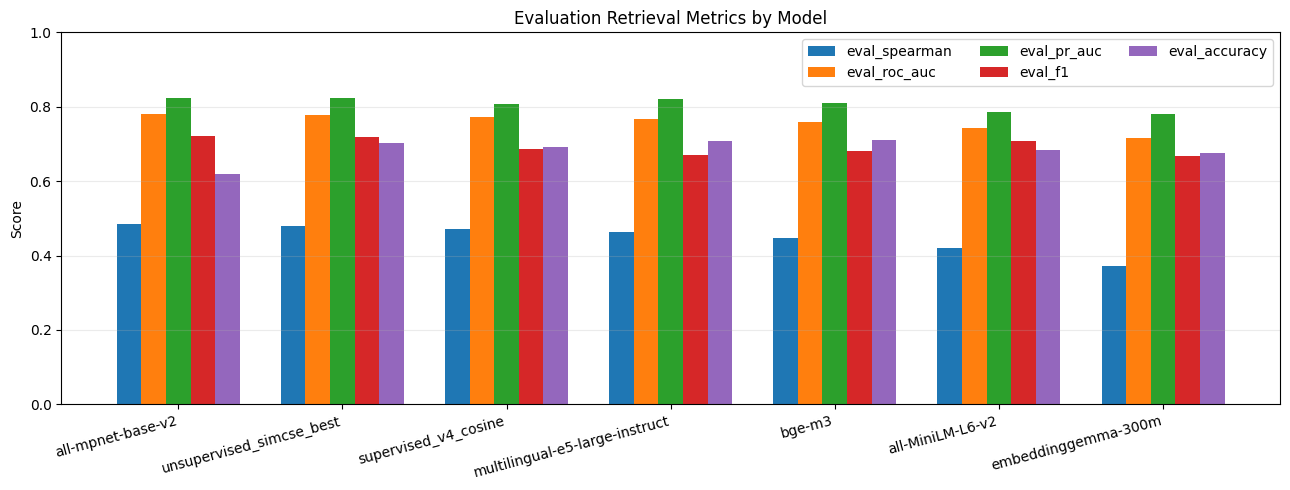

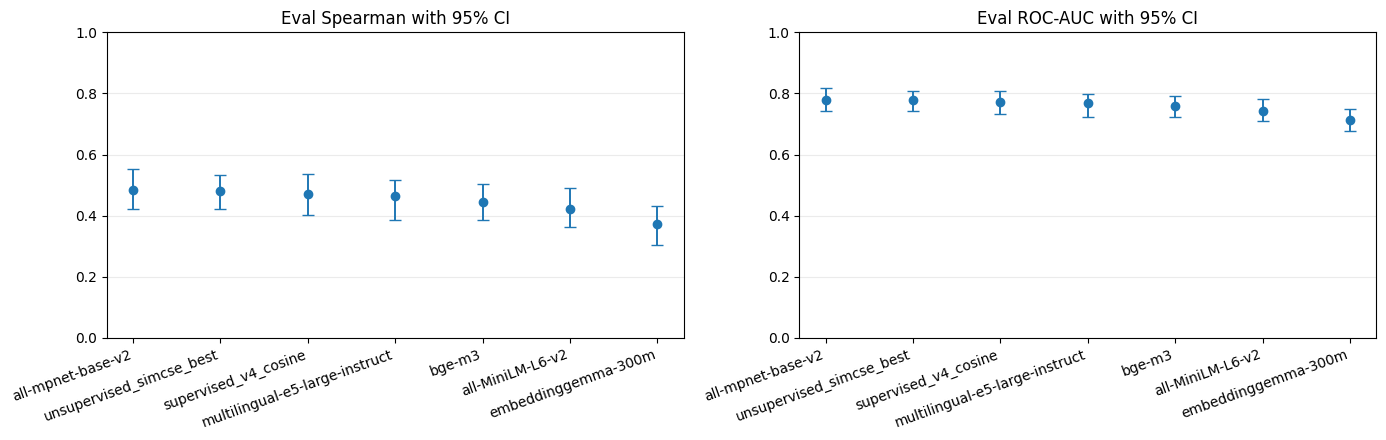

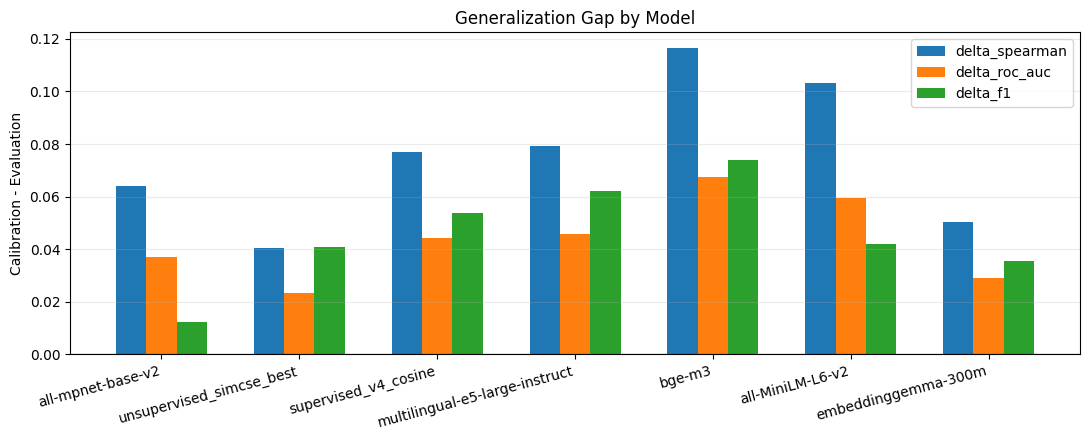

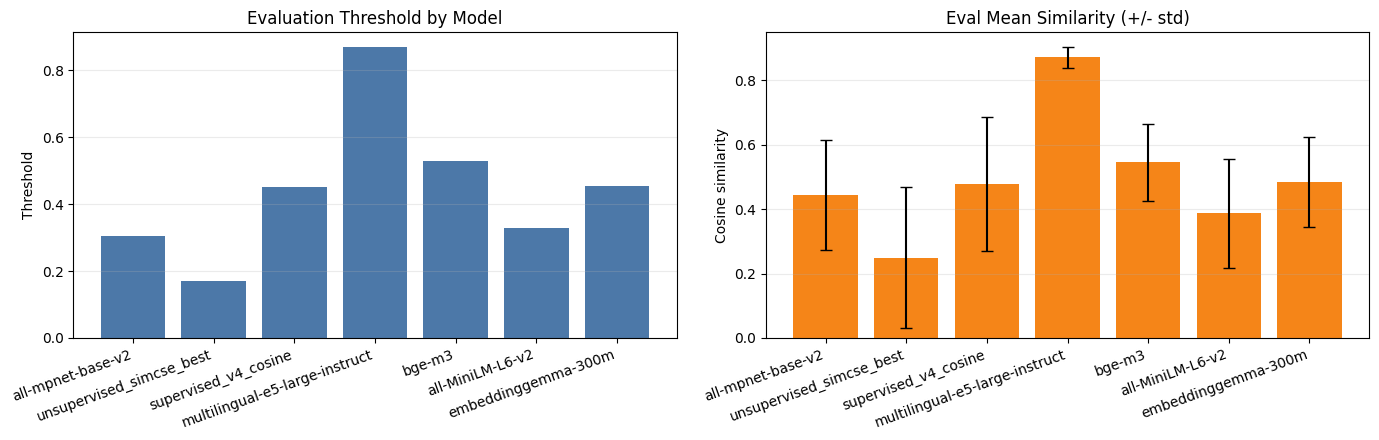

In [22]:
# 09b_Retrieval_Graphs
# Purpose: Visualize retrieval metrics, confidence intervals, calibration deltas, and threshold/similarity diagnostics.

if "DASHBOARD_METRICS_DF" not in globals() or DASHBOARD_METRICS_DF.empty:
    raise RuntimeError("Run 09a_Full_Metrics_Table_From_Artifacts before plotting retrieval graphs.")

ordered_df = DASHBOARD_METRICS_DF.copy()
ordered_df["model_name"] = pd.Categorical(ordered_df["model_name"], categories=DASHBOARD_MODEL_ORDER, ordered=True)
ordered_df = ordered_df.sort_values("model_name").reset_index(drop=True)

# 1) Grouped bar chart for evaluation metrics
metric_cols = ["eval_spearman", "eval_roc_auc", "eval_pr_auc", "eval_f1", "eval_accuracy"]
x = np.arange(len(ordered_df))
width = 0.15
fig, ax = plt.subplots(figsize=(13, 5))
for i, col in enumerate(metric_cols):
    ax.bar(x + (i - 2) * width, ordered_df[col].values, width=width, label=col)
ax.set_xticks(x)
ax.set_xticklabels(ordered_df["model_name"], rotation=15, ha="right")
ax.set_ylim(0.0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Evaluation Retrieval Metrics by Model")
ax.legend(loc="upper right", ncol=3)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 2) Confidence interval chart for eval Spearman and ROC-AUC
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
ci_specs = [
    ("eval_spearman", "eval_spearman_ci_low", "eval_spearman_ci_high", "Eval Spearman with 95% CI"),
    ("eval_roc_auc", "eval_roc_auc_ci_low", "eval_roc_auc_ci_high", "Eval ROC-AUC with 95% CI"),
]
for ax, (metric, low_col, high_col, title) in zip(axes, ci_specs):
    y = ordered_df[metric].to_numpy(dtype=float)
    low = ordered_df[low_col].to_numpy(dtype=float)
    high = ordered_df[high_col].to_numpy(dtype=float)
    yerr = np.vstack([y - low, high - y])
    ax.errorbar(x, y, yerr=yerr, fmt="o", capsize=4, linewidth=1.4)
    ax.set_xticks(x)
    ax.set_xticklabels(ordered_df["model_name"], rotation=20, ha="right")
    ax.set_title(title)
    ax.set_ylim(0.0, 1.0)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 3) Calibration-vs-evaluation deltas
fig, ax = plt.subplots(figsize=(11, 4.5))
delta_cols = ["delta_spearman", "delta_roc_auc", "delta_f1"]
width = 0.22
for i, col in enumerate(delta_cols):
    ax.bar(x + (i - 1) * width, ordered_df[col].values, width=width, label=col)
ax.set_xticks(x)
ax.set_xticklabels(ordered_df["model_name"], rotation=15, ha="right")
ax.set_ylabel("Calibration - Evaluation")
ax.set_title("Generalization Gap by Model")
ax.axhline(0.0, color="black", linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# 4) Threshold + similarity scale diagnostics
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
axes[0].bar(x, ordered_df["eval_threshold"].values, color="#4C78A8")
axes[0].set_xticks(x)
axes[0].set_xticklabels(ordered_df["model_name"], rotation=20, ha="right")
axes[0].set_title("Evaluation Threshold by Model")
axes[0].set_ylabel("Threshold")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(x, ordered_df["eval_mean_similarity"].values, yerr=ordered_df["eval_std_similarity"].values, capsize=4, color="#F58518")
axes[1].set_xticks(x)
axes[1].set_xticklabels(ordered_df["model_name"], rotation=20, ha="right")
axes[1].set_title("Eval Mean Similarity (+/- std)")
axes[1].set_ylabel("Cosine similarity")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [23]:
# 10_Full_Corpus_Embedding_Extraction
# Purpose: Encode the full incident corpus for each evaluated top model to support clustering and graph analysis.

CLUSTER_MODEL_LIMIT = 3
CLUSTER_RETRIEVAL_TABLE = RETRIEVAL_TABLE.head(CLUSTER_MODEL_LIMIT).copy()
print("cluster_models:", CLUSTER_RETRIEVAL_TABLE["model_name"].tolist())

EMBEDDINGS = pipeline.encode_corpus(
    CLUSTER_RETRIEVAL_TABLE,
    MODEL_METRICS,
    LOADED_MODELS,
    DEVICE,
    DATA_BUNDLE["corpus_texts"],
    CONFIG["eval"]["batch_size"],
)
print({k: v.shape for k, v in EMBEDDINGS.items()})


cluster_models: ['all-mpnet-base-v2', 'unsupervised_simcse_best', 'supervised_v4_cosine']


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

{'all-mpnet-base-v2': (1000, 768), 'unsupervised_simcse_best': (1000, 768), 'supervised_v4_cosine': (1000, 768)}


In [24]:
# 11_HDBSCAN_Cluster_Discovery
# Purpose: Discover natural cluster structure with HDBSCAN and capture discovered cluster counts.

CLUSTER_RESULTS, CLUSTER_LABELS, HDBSCAN_DISCOVERED_K = pipeline.run_hdbscan(EMBEDDINGS, CONFIG)
print("hdbscan_discovered_k:", HDBSCAN_DISCOVERED_K)


hdbscan_discovered_k: []


In [25]:
# 12_KMeans_Comparable_Clustering
# Purpose: Run comparable KMeans clustering across models using a shared K derived from HDBSCAN.

CLUSTER_RESULTS, CLUSTER_CENTROIDS, GLOBAL_K = pipeline.run_kmeans(
    EMBEDDINGS, CLUSTER_RESULTS, CLUSTER_LABELS, HDBSCAN_DISCOVERED_K, CONFIG
)
CLUSTER_EXTERNAL_METRICS = pipeline.compute_cluster_external_metrics(
    CLUSTER_LABELS,
    DATA_BUNDLE.get("cluster_weak_labels", {}),
)
print("global_k:", GLOBAL_K)
print("cluster_external_metrics:", CLUSTER_EXTERNAL_METRICS)


global_k: 10
cluster_external_metrics: {'all-mpnet-base-v2': {'kmeans': {'assignment_group': {'n_samples': 1000, 'n_true_labels': 20, 'n_clusters': 10, 'nmi': 0.15929491499556592, 'ari': 0.03155634992859124, 'purity': 0.385}, 'subcategory': {'n_samples': 929, 'n_true_labels': 13, 'n_clusters': 10, 'nmi': 0.08981577765923632, 'ari': 0.02401171802237131, 'purity': 0.395048439181916}, 'service': {'n_samples': 1000, 'n_true_labels': 5, 'n_clusters': 10, 'nmi': 0.14013133964659838, 'ari': 0.0474662586369251, 'purity': 0.587}, 'aggregate': {'mean_nmi': 0.12974734410046687, 'mean_ari': 0.034344775529295886, 'mean_purity': 0.4556828130606387}}}, 'unsupervised_simcse_best': {'kmeans': {'assignment_group': {'n_samples': 1000, 'n_true_labels': 20, 'n_clusters': 10, 'nmi': 0.127455092846977, 'ari': 0.010805400771959527, 'purity': 0.361}, 'subcategory': {'n_samples': 929, 'n_true_labels': 13, 'n_clusters': 10, 'nmi': 0.08554393702684657, 'ari': 0.017631167966806173, 'purity': 0.38643702906350913}, 

cluster_metrics_table:


,model_name,hdbscan_available,hdbscan_reason,hdbscan_n_clusters,hdbscan_noise_ratio,hdbscan_silhouette,kmeans_n_clusters,kmeans_silhouette,kmeans_calinski_harabasz,kmeans_davies_bouldin
0,all-mpnet-base-v2,False,No module named 'hdbscan',NaN,NaN,NaN,10.0,0.080279,35.711668,2.764934
1,unsupervised_simcse_best,False,No module named 'hdbscan',NaN,NaN,NaN,10.0,0.081189,34.281449,2.767120
2,supervised_v4_cosine,False,No module named 'hdbscan',NaN,NaN,NaN,10.0,0.080180,38.489765,2.869768
3,multilingual-e5-large-instruct,False,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,bge-m3,False,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,all-MiniLM-L6-v2,False,,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,embeddinggemma-300m,False,,NaN,NaN,NaN,NaN,NaN,NaN,NaN


hdbscan_status:


,model_name,hdbscan_available,hdbscan_reason,hdbscan_n_clusters,hdbscan_noise_ratio
0,all-mpnet-base-v2,False,No module named 'hdbscan',NaN,NaN
1,unsupervised_simcse_best,False,No module named 'hdbscan',NaN,NaN
2,supervised_v4_cosine,False,No module named 'hdbscan',NaN,NaN
3,multilingual-e5-large-instruct,False,,NaN,NaN
4,bge-m3,False,,NaN,NaN
5,all-MiniLM-L6-v2,False,,NaN,NaN
6,embeddinggemma-300m,False,,NaN,NaN


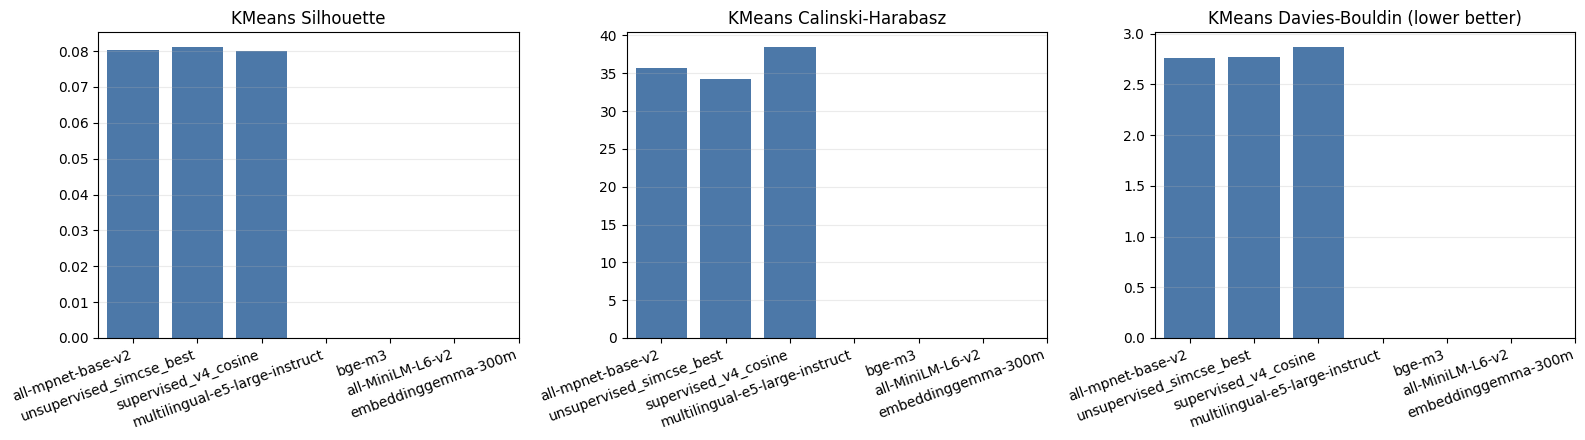

In [26]:
# 12a_Cluster_Metrics_Dashboard
# Purpose: Show clustering diagnostics from artifact payload (KMeans and HDBSCAN status).

cluster_summary = ARTIFACT_BUNDLE["payload"].get("cluster_summary", {})
per_model = cluster_summary.get("per_model", {})
if not per_model:
    raise RuntimeError("No cluster_summary.per_model found in artifact payload.")

rows = []
model_order = DASHBOARD_MODEL_ORDER if "DASHBOARD_MODEL_ORDER" in globals() else list(per_model.keys())
for model_name in model_order:
    model_payload = per_model.get(model_name, {})
    hdb = model_payload.get("hdbscan", {})
    km = model_payload.get("kmeans", {})
    rows.append(
        {
            "model_name": model_name,
            "hdbscan_available": hdb.get("available", False),
            "hdbscan_reason": hdb.get("reason", ""),
            "hdbscan_n_clusters": hdb.get("n_clusters", float("nan")),
            "hdbscan_noise_ratio": hdb.get("noise_ratio", float("nan")),
            "hdbscan_silhouette": hdb.get("silhouette", float("nan")),
            "kmeans_n_clusters": km.get("n_clusters", float("nan")),
            "kmeans_silhouette": km.get("silhouette", float("nan")),
            "kmeans_calinski_harabasz": km.get("calinski_harabasz", float("nan")),
            "kmeans_davies_bouldin": km.get("davies_bouldin", float("nan")),
        }
    )

DASHBOARD_CLUSTER_METRICS_DF = pd.DataFrame(rows)
print("cluster_metrics_table:")
display(DASHBOARD_CLUSTER_METRICS_DF)

print("hdbscan_status:")
display(DASHBOARD_CLUSTER_METRICS_DF[["model_name", "hdbscan_available", "hdbscan_reason", "hdbscan_n_clusters", "hdbscan_noise_ratio"]])

plot_df = DASHBOARD_CLUSTER_METRICS_DF.copy()
plot_df["model_name"] = pd.Categorical(plot_df["model_name"], categories=model_order, ordered=True)
plot_df = plot_df.sort_values("model_name")
x = np.arange(len(plot_df))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
plot_specs = [
    ("kmeans_silhouette", "KMeans Silhouette"),
    ("kmeans_calinski_harabasz", "KMeans Calinski-Harabasz"),
    ("kmeans_davies_bouldin", "KMeans Davies-Bouldin (lower better)"),
]
for ax, (col, title) in zip(axes, plot_specs):
    ax.bar(x, plot_df[col].to_numpy(dtype=float), color="#4C78A8")
    ax.set_xticks(x)
    ax.set_xticklabels(plot_df["model_name"], rotation=20, ha="right")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [27]:
# 13_Common_Issues_From_Clusters
# Purpose: Extract common issue terms and representative incidents per cluster for interpretability.

CLUSTER_REPORT_DF = pipeline.build_cluster_context(
    EMBEDDINGS,
    CLUSTER_LABELS,
    CLUSTER_CENTROIDS,
    DATA_BUNDLE.get("artifact_corpus_texts", DATA_BUNDLE["corpus_texts"]),
    OUTPUT_ROOT,
)
print(CLUSTER_REPORT_DF.head(10).to_string(index=False))


       model_name cluster_algo  cluster_id  cluster_size                                               top_terms                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     representative_text_1                                                                                                                                                                                                                                                                                                                                                                                              

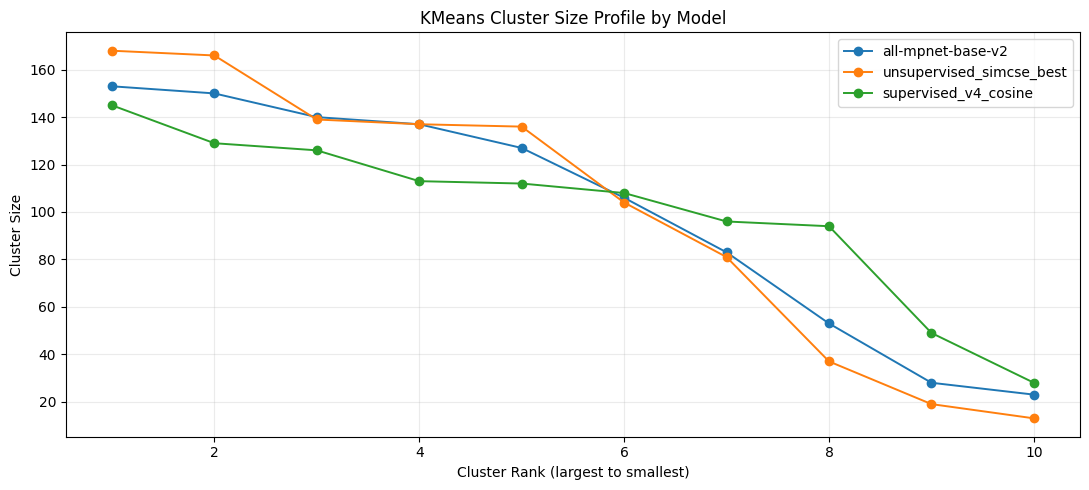

top_20_largest_kmeans_clusters:


,model_name,cluster_id,cluster_size,top_terms,representative_text_1,representative_text_2
20,unsupervised_simcse_best,2,168,error | check | user | message | posting,i cannot able to proceed due to this error. se...,user : rosemarie ( ac accounting) edo-s1-24003...
21,unsupervised_simcse_best,3,166,report | help | 2024 | check | sales,help to check inventory ledger report (y0gco_0...,"ap revaluation in apr 24, had missing revaluat..."
0,all-mpnet-base-v2,3,153,order | sales | sales order | purchase | purch...,user: lilibeth caspe/ jian hui issue: edo-s1-2...,pph-sales order-2403004838 - did not proceed t...
1,all-mpnet-base-v2,7,150,error | check | user | file | posting,there is an einvoice: 9117 posting failed due ...,i cannot able to proceed due to this error. se...
10,supervised_v4_cosine,2,145,error | check | user | file | posting,user: jian hui issue: epo posting failed epo-s...,"shirish/khanh, assist to check the following f..."
2,all-mpnet-base-v2,2,140,user | attached | email | report | check,refer attached for further info gerald: 24/4/2...,"support, advise any changes done from your end..."
22,unsupervised_simcse_best,6,139,user | attached | email | check | help,"check why 78116cbm, 78116dbl & 78116dpc is mis...",to re-assign eiaf approval of mr. genaro castr...
23,unsupervised_simcse_best,9,137,order | purchase | sales | purchase order | sa...,user : bee bee ( bog) issue : incorrect mark c...,"we check the job log, all job finished with so..."
3,all-mpnet-base-v2,9,137,help | report | check | price | sales,we would like to report that there are some di...,help to check inventory ledger report (y0gco_0...
24,unsupervised_simcse_best,5,136,sap | order | sales | error | sales order,check this delivery order 3000786322 cannot in...,sap part had been delivered but data not sync ...


In [28]:
# 13a_Cluster_Report_Visuals
# Purpose: Visualize cluster size distribution and display largest cluster contexts.

cluster_df = ARTIFACT_BUNDLE.get("cluster_df", pd.DataFrame()).copy()
if cluster_df.empty:
    print("[warn] cluster_report.csv could not be loaded or is empty.")
else:
    kmeans_df = cluster_df.loc[cluster_df["cluster_algo"] == "kmeans"].copy()
    if kmeans_df.empty:
        print("[warn] No kmeans rows found in cluster_report.csv.")
    else:
        kmeans_df["cluster_size"] = kmeans_df["cluster_size"].astype(int)
        model_order = DASHBOARD_MODEL_ORDER if "DASHBOARD_MODEL_ORDER" in globals() else sorted(kmeans_df["model_name"].unique().tolist())

        fig, ax = plt.subplots(figsize=(11, 5))
        for model_name in model_order:
            sizes = sorted(kmeans_df.loc[kmeans_df["model_name"] == model_name, "cluster_size"].tolist(), reverse=True)
            if not sizes:
                continue
            ax.plot(range(1, len(sizes) + 1), sizes, marker="o", linewidth=1.4, label=model_name)
        ax.set_title("KMeans Cluster Size Profile by Model")
        ax.set_xlabel("Cluster Rank (largest to smallest)")
        ax.set_ylabel("Cluster Size")
        ax.grid(alpha=0.25)
        ax.legend()
        plt.tight_layout()
        plt.show()

        top_n = 20
        TOP_CLUSTER_TABLE = kmeans_df.sort_values("cluster_size", ascending=False).head(top_n)[
            ["model_name", "cluster_id", "cluster_size", "top_terms", "representative_text_1", "representative_text_2"]
        ]
        print(f"top_{top_n}_largest_kmeans_clusters:")
        display(TOP_CLUSTER_TABLE)

In [29]:
# 14_Semantic_KNN_Graphs
# Purpose: Build and save semantic kNN graphs for each model using full-corpus embeddings.

GRAPH_SUMMARY = pipeline.build_semantic_graphs(EMBEDDINGS, CLUSTER_LABELS, CONFIG, OUTPUT_ROOT)
print(GRAPH_SUMMARY)


{'all-mpnet-base-v2': {'nodes': 1000, 'edges': 7584, 'avg_degree': 15.168, 'n_components': 9, 'min_edge_weight': 0.35, 'graph_path': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\models\\supervised_vs_unsupervised_analysis\\20260212_080942\\semantic_graph_all-mpnet-base-v2.png'}, 'unsupervised_simcse_best': {'nodes': 1000, 'edges': 4016, 'avg_degree': 8.032, 'n_components': 61, 'min_edge_weight': 0.35, 'graph_path': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\models\\supervised_vs_unsupervised_analysis\\20260212_080942\\semantic_graph_unsupervised_simcse_best.png'}, 'supervised_v4_cosine': {'nodes': 1000, 'edges': 7748, 'avg_degree': 15.496, 'n_components': 12, 'min_edge_weight': 0.35, 'graph_path': 'C:\\Users\\donov\\Documents\\itsm project\\Final_nexustism\\nexustism\\models\\supervised_vs_unsupervised_analysis\\20260212_080942\\semantic_graph_supervised_v4_cosine.png'}}


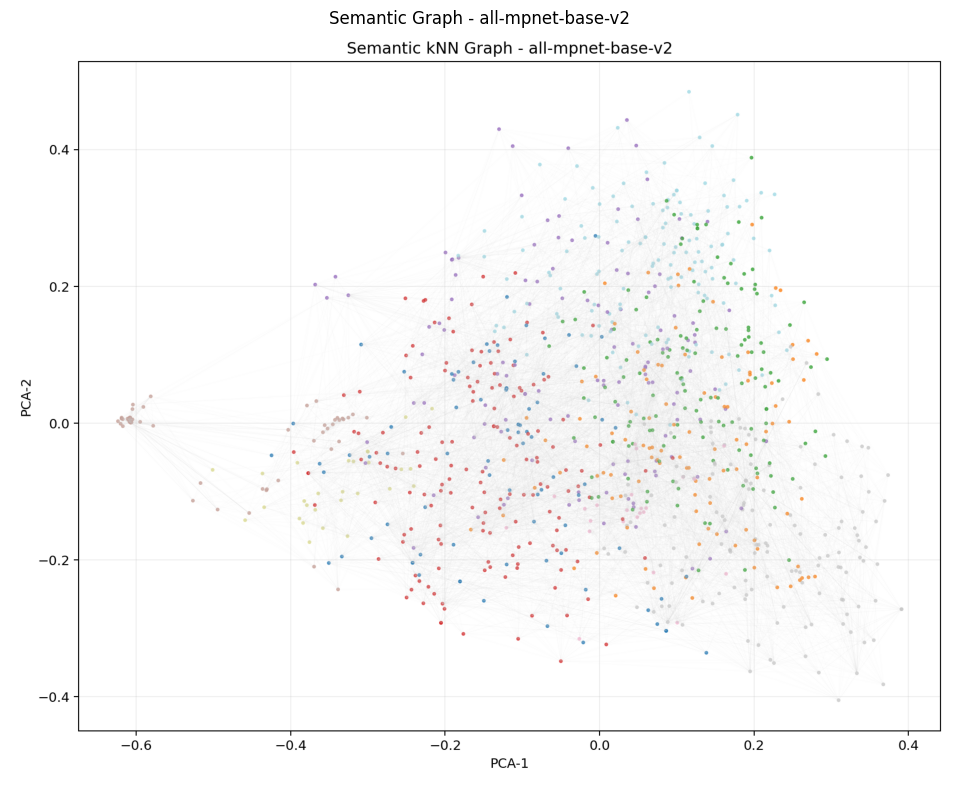

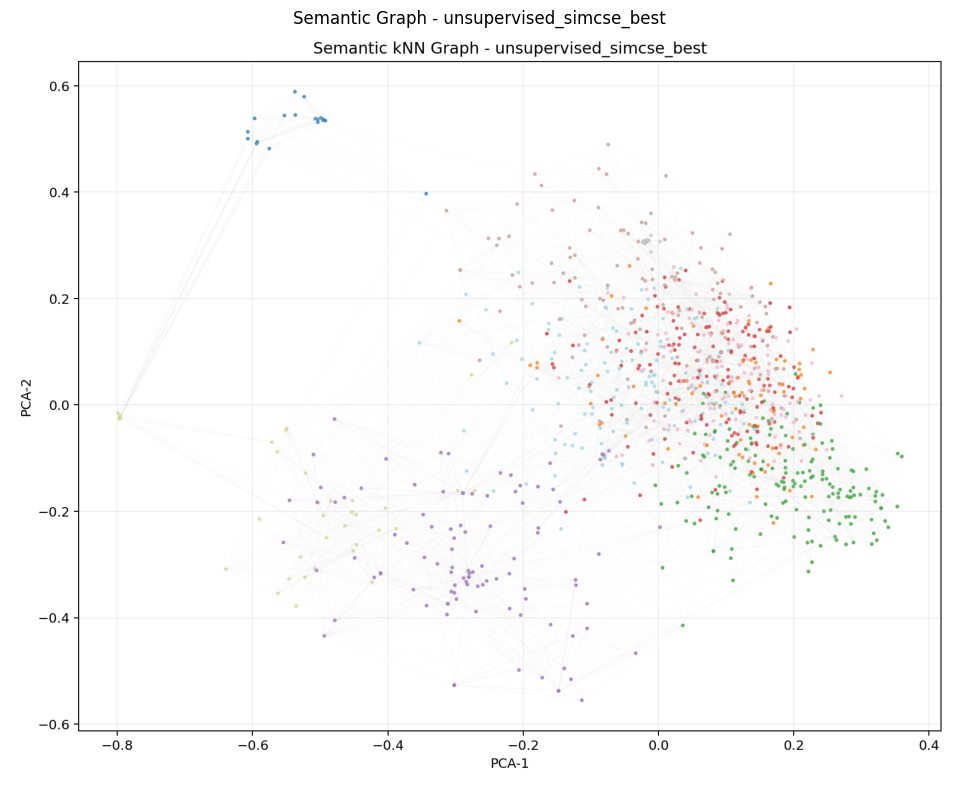

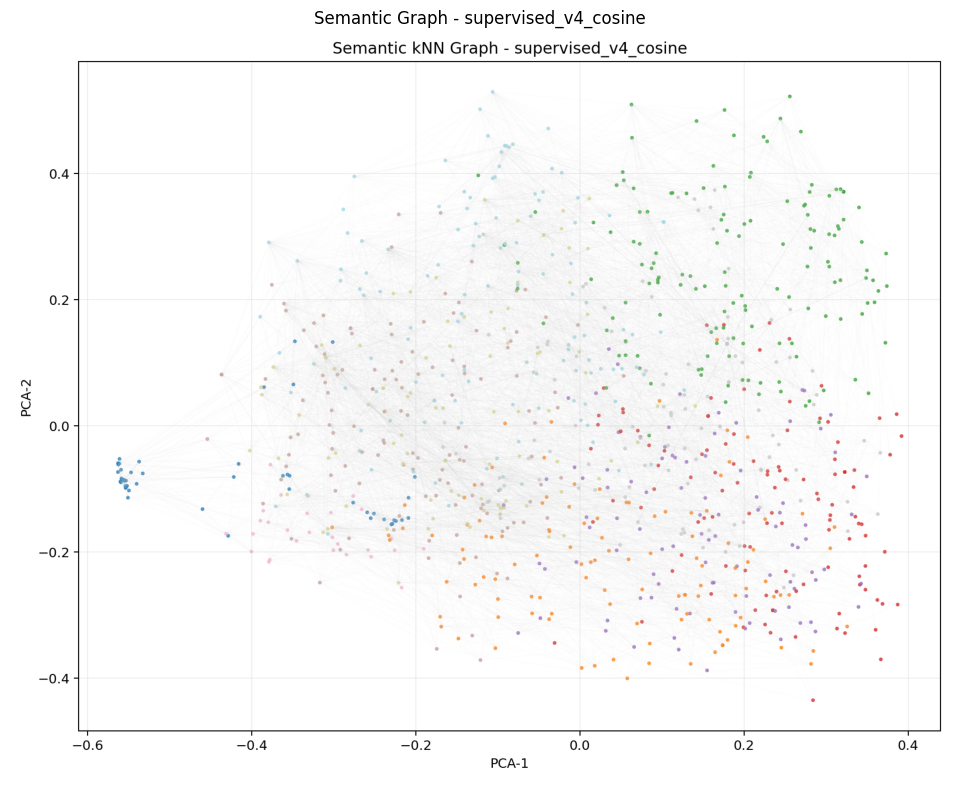

[warn] Missing graph path for model: multilingual-e5-large-instruct
[warn] Missing graph path for model: bge-m3
[warn] Missing graph path for model: all-MiniLM-L6-v2
[warn] Missing graph path for model: embeddinggemma-300m


In [30]:
# 14a_Inline_Semantic_Graphs_From_Artifacts
# Purpose: Render saved semantic graph images inline from artifact payload paths.

graph_paths = ARTIFACT_BUNDLE.get("graph_paths", {})
if not graph_paths:
    print("[warn] No graph paths found in artifact payload.")
else:
    display_order = DASHBOARD_MODEL_ORDER if "DASHBOARD_MODEL_ORDER" in globals() else list(graph_paths.keys())
    for model_name in display_order:
        graph_path = graph_paths.get(model_name)
        if graph_path is None:
            print(f"[warn] Missing graph path for model: {model_name}")
            continue
        graph_path = Path(graph_path)
        if not graph_path.exists():
            print(f"[warn] Graph image not found for {model_name}: {graph_path}")
            continue

        img = plt.imread(graph_path)
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.imshow(img)
        ax.set_title(f"Semantic Graph - {model_name}")
        ax.axis("off")
        plt.tight_layout()
        plt.show()

In [31]:
# 15_Method_Level_Comparison_And_Winner
# Purpose: Compare supervised vs unsupervised methods and compute the final winner summary.

METHOD_CLUSTER_SUMMARY, WINNER = pipeline.summarize_methods(RETRIEVAL_TABLE, CLUSTER_RESULTS)
print("method_summary:", METHOD_SUMMARY)
print("method_cluster_summary:", METHOD_CLUSTER_SUMMARY)
print("winner:", WINNER)


method_summary: {'baseline': {'best_model': 'all-mpnet-base-v2', 'best_spearman': 0.4837235115398561, 'best_roc_auc': 0.7792734693877552, 'best_f1': 0.721584984358707, 'median_spearman': 0.4520785621846347, 'median_roc_auc': 0.7610040816326531, 'median_f1': 0.7148215542665397}, 'supervised': {'best_model': 'supervised_v4_cosine', 'best_spearman': 0.47088492723729874, 'best_roc_auc': 0.771861224489796, 'best_f1': 0.686046511627907, 'median_spearman': 0.47088492723729874, 'median_roc_auc': 0.771861224489796, 'median_f1': 0.686046511627907}, 'unsupervised': {'best_model': 'unsupervised_simcse_best', 'best_spearman': 0.480160379070532, 'best_roc_auc': 0.7772163265306125, 'best_f1': 0.7181571815718157, 'median_spearman': 0.480160379070532, 'median_roc_auc': 0.7772163265306125, 'median_f1': 0.7181571815718157}}
method_cluster_summary: {'baseline': {'median_kmeans_silhouette': 0.08027862757444382, 'best_kmeans_silhouette': 0.08027862757444382}, 'supervised': {'median_kmeans_silhouette': 0.080

In [32]:
# 15a_Winner_Diagnostics
# Purpose: Add tie-aware diagnostics using pairwise margins and CI overlap flags.

if "DASHBOARD_METRICS_DF" not in globals() or DASHBOARD_METRICS_DF.empty:
    raise RuntimeError("Run 09a_Full_Metrics_Table_From_Artifacts before winner diagnostics.")

winner_payload = ARTIFACT_BUNDLE["payload"].get("winner", {})
ordered_df = DASHBOARD_METRICS_DF.sort_values(
    ["eval_spearman", "eval_roc_auc", "eval_f1"], ascending=[False, False, False]
).reset_index(drop=True)

top = ordered_df.iloc[0]
diag_rows = []
for _, row in ordered_df.iterrows():
    overlap_spearman_ci = not (
        (top["eval_spearman_ci_high"] < row["eval_spearman_ci_low"]) or
        (row["eval_spearman_ci_high"] < top["eval_spearman_ci_low"])
    )
    overlap_roc_auc_ci = not (
        (top["eval_roc_auc_ci_high"] < row["eval_roc_auc_ci_low"]) or
        (row["eval_roc_auc_ci_high"] < top["eval_roc_auc_ci_low"])
    )
    diag_rows.append(
        {
            "model_name": row["model_name"],
            "method_type": row["method_type"],
            "delta_vs_top_spearman": float(top["eval_spearman"] - row["eval_spearman"]),
            "delta_vs_top_roc_auc": float(top["eval_roc_auc"] - row["eval_roc_auc"]),
            "delta_vs_top_f1": float(top["eval_f1"] - row["eval_f1"]),
            "spearman_ci_overlaps_top": bool(overlap_spearman_ci),
            "roc_auc_ci_overlaps_top": bool(overlap_roc_auc_ci),
            "practically_tied_with_top": bool(overlap_spearman_ci and overlap_roc_auc_ci),
        }
    )

DASHBOARD_WINNER_DIAGNOSTICS_DF = pd.DataFrame(diag_rows)

print("artifact_winner_payload:")
print(winner_payload)
print("winner_diagnostics:")
display(DASHBOARD_WINNER_DIAGNOSTICS_DF)

artifact_winner_payload:
{'winner_model': 'all-mpnet-base-v2', 'winner_method_type': 'baseline', 'decision_rule': 'retrieval_only_spearman_then_roc_auc_then_f1__hdbscan_unavailable', 'retrieval_metrics': {'spearman': 0.4837235115398561, 'roc_auc': 0.7792734693877552, 'pr_auc': 0.822956047098806, 'f1': 0.721584984358707}, 'cluster_evidence': {'excluded': True, 'reason': 'HDBSCAN unavailable across evaluated models; cluster evidence removed from winner rationale.'}}
winner_diagnostics:


,model_name,method_type,delta_vs_top_spearman,delta_vs_top_roc_auc,delta_vs_top_f1,spearman_ci_overlaps_top,roc_auc_ci_overlaps_top,practically_tied_with_top
0,all-mpnet-base-v2,baseline,0.000000,0.000000,0.000000,True,True,True
1,unsupervised_simcse_best,unsupervised,0.003563,0.002057,0.003428,True,True,True
2,supervised_v4_cosine,supervised,0.012839,0.007412,0.035538,True,True,True
3,multilingual-e5-large-instruct,baseline,0.019730,0.011388,0.050638,True,True,True
4,bge-m3,baseline,0.037271,0.021518,0.040266,True,True,True
5,all-MiniLM-L6-v2,baseline,0.063290,0.036539,0.013527,True,True,True
6,embeddinggemma-300m,baseline,0.111833,0.064563,0.054918,True,True,True


In [33]:
# 16_Save_Artifacts_And_Run_Report
# Purpose: Persist metrics, cluster reports, graphs, and markdown summary artifacts for this run.

PAYLOAD = pipeline.save_artifacts(
    OUTPUT_ROOT,
    RUN_TIMESTAMP,
    PROJECT_ROOT,
    DEVICE,
    CONFIG,
    DATA_BUNDLE,
    FAILED_MODELS,
    MODEL_METRICS,
    METHOD_SUMMARY,
    METHOD_CLUSTER_SUMMARY,
    GLOBAL_K,
    HDBSCAN_DISCOVERED_K,
    CLUSTER_RESULTS,
    GRAPH_SUMMARY,
    WINNER,
    RETRIEVAL_TABLE,
    SIMCSE_SWEEP_RESULTS,
    data_profile=DATA_BUNDLE.get("data_profile", {}),
    ranking_eval_health=globals().get("RANKING_EVAL_HEALTH", {}),
    cluster_external_metrics=globals().get("CLUSTER_EXTERNAL_METRICS", {}),
)

metrics_json_path = OUTPUT_ROOT / "metrics.json"
print("metrics_json:", metrics_json_path)
print("summary_md:", OUTPUT_ROOT / "summary.md")
print("payload_keys:", list(PAYLOAD.keys()))

if 'ARTIFACT_SELECTED_DIR' in globals():
    print('dashboard_artifact_run_dir:', ARTIFACT_SELECTED_DIR)
else:
    print('dashboard_artifact_run_dir: <not resolved>')
print('dashboard_sections:', ['09a_Full_Metrics_Table_From_Artifacts', '09b_Retrieval_Graphs', '12a_Cluster_Metrics_Dashboard', '13a_Cluster_Report_Visuals', '14a_Inline_Semantic_Graphs_From_Artifacts', '15a_Winner_Diagnostics'])


metrics_json: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260212_080942\metrics.json
summary_md: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260212_080942\summary.md
payload_keys: ['run_metadata', 'model_metrics', 'method_summary', 'cluster_summary', 'graph_summary', 'winner', 'data_profile', 'ranking_eval_health', 'cluster_external_metrics']
dashboard_artifact_run_dir: C:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\supervised_vs_unsupervised_analysis\20260211_091833
dashboard_sections: ['09a_Full_Metrics_Table_From_Artifacts', '09b_Retrieval_Graphs', '12a_Cluster_Metrics_Dashboard', '13a_Cluster_Report_Visuals', '14a_Inline_Semantic_Graphs_From_Artifacts', '15a_Winner_Diagnostics']


# Recommendations & Extended Analysis
The following cells address methodological gaps identified during critique:
1. **BM25/TF-IDF Baseline** - Proves whether embeddings add value over bag-of-words
2. **Retrieval Metrics (NDCG@k, MRR)** - Production-relevant ranking evaluation
3. **Paired Bootstrap Significance Testing** - Statistical rigor for model comparisons
4. **Error Analysis** - Identifies failure modes and borderline cases
5. **Computational Cost Benchmarks** - Latency, throughput, memory per model
6. **Train/Eval Distribution Comparison** - Investigates supervised model underperformance

In [34]:
# R1_BM25_TFIDF_Baseline_Evaluation
# Purpose: Evaluate TF-IDF and BM25 bag-of-words baselines to contextualize embedding model value.

print("Computing TF-IDF cosine similarity baseline...")
tfidf_cal_scores = tfidf_cosine_scores(
    DATA_BUNDLE["calibration_data"]["texts1"],
    DATA_BUNDLE["calibration_data"]["texts2"],
)
tfidf_eval_scores = tfidf_cosine_scores(
    DATA_BUNDLE["evaluation_data"]["texts1"],
    DATA_BUNDLE["evaluation_data"]["texts2"],
)
tfidf_threshold, _ = calibrate_threshold(DATA_BUNDLE["calibration_data"]["labels"], tfidf_cal_scores)
tfidf_metrics = retrieval_metrics(
    DATA_BUNDLE["evaluation_data"]["labels"],
    tfidf_eval_scores,
    tfidf_threshold,
    CONFIG["eval"]["bootstrap_iters"],
    CONFIG["seed"],
)
print(f"TF-IDF Baseline -> Spearman={tfidf_metrics['spearman']:.4f}, ROC-AUC={tfidf_metrics['roc_auc']:.4f}, F1={tfidf_metrics['f1']:.4f}")

print("\nComputing BM25 similarity baseline...")
bm25_cal_scores = bm25_scores(
    DATA_BUNDLE["calibration_data"]["texts1"],
    DATA_BUNDLE["calibration_data"]["texts2"],
)
bm25_eval_scores = bm25_scores(
    DATA_BUNDLE["evaluation_data"]["texts1"],
    DATA_BUNDLE["evaluation_data"]["texts2"],
)
bm25_threshold, _ = calibrate_threshold(DATA_BUNDLE["calibration_data"]["labels"], bm25_cal_scores)
bm25_metrics = retrieval_metrics(
    DATA_BUNDLE["evaluation_data"]["labels"],
    bm25_eval_scores,
    bm25_threshold,
    CONFIG["eval"]["bootstrap_iters"],
    CONFIG["seed"],
)
print(f"BM25 Baseline   -> Spearman={bm25_metrics['spearman']:.4f}, ROC-AUC={bm25_metrics['roc_auc']:.4f}, F1={bm25_metrics['f1']:.4f}")

# Add to model metrics for comparison
MODEL_METRICS["tfidf_baseline"] = {
    "model_name": "tfidf_baseline",
    "method_type": "lexical_baseline",
    "source": "sklearn",
    "path_or_id": "TF-IDF cosine",
    "metrics": {"calibration": {}, "evaluation": tfidf_metrics},
}
MODEL_METRICS["bm25_baseline"] = {
    "model_name": "bm25_baseline",
    "method_type": "lexical_baseline",
    "source": "sklearn",
    "path_or_id": "BM25",
    "metrics": {"calibration": {}, "evaluation": bm25_metrics},
}

# Comparison table
baseline_comparison = pd.DataFrame([
    {"Method": "TF-IDF (bag-of-words)", "Spearman": tfidf_metrics["spearman"], "ROC-AUC": tfidf_metrics["roc_auc"], "F1": tfidf_metrics["f1"]},
    {"Method": "BM25 (term weighting)", "Spearman": bm25_metrics["spearman"], "ROC-AUC": bm25_metrics["roc_auc"], "F1": bm25_metrics["f1"]},
])

# Add best embedding model for reference
if MODEL_METRICS:
    best_emb = max(
        [(k, v) for k, v in MODEL_METRICS.items() if v["method_type"] != "lexical_baseline"],
        key=lambda x: x[1]["metrics"]["evaluation"].get("spearman", 0),
        default=None,
    )
    if best_emb:
        emb_eval = best_emb[1]["metrics"]["evaluation"]
        baseline_comparison = pd.concat([baseline_comparison, pd.DataFrame([{
            "Method": f"Best Embedding ({best_emb[0]})",
            "Spearman": emb_eval["spearman"],
            "ROC-AUC": emb_eval["roc_auc"],
            "F1": emb_eval["f1"],
        }])], ignore_index=True)

print("\n=== Lexical vs Embedding Comparison ===")
display(baseline_comparison)

embedding_lift = None
if best_emb:
    embedding_lift = {
        "spearman_lift_over_tfidf": best_emb[1]["metrics"]["evaluation"]["spearman"] - tfidf_metrics["spearman"],
        "spearman_lift_over_bm25": best_emb[1]["metrics"]["evaluation"]["spearman"] - bm25_metrics["spearman"],
        "roc_auc_lift_over_tfidf": best_emb[1]["metrics"]["evaluation"]["roc_auc"] - tfidf_metrics["roc_auc"],
        "roc_auc_lift_over_bm25": best_emb[1]["metrics"]["evaluation"]["roc_auc"] - bm25_metrics["roc_auc"],
    }
    print("\n=== Embedding Value-Add ===")
    for k, v in embedding_lift.items():
        direction = "+" if v > 0 else ""
        print(f"  {k}: {direction}{v:.4f}")

Computing TF-IDF cosine similarity baseline...
TF-IDF Baseline -> Spearman=0.4119, ROC-AUC=0.7372, F1=0.6667

Computing BM25 similarity baseline...
BM25 Baseline   -> Spearman=0.4319, ROC-AUC=0.7487, F1=0.6638

=== Lexical vs Embedding Comparison ===


,Method,Spearman,ROC-AUC,F1
0,TF-IDF (bag-of-words),0.411932,0.737163,0.666667
1,BM25 (term weighting),0.431899,0.748661,0.663755
2,Best Embedding (all-mpnet-base-v2),0.483724,0.779273,0.721585



=== Embedding Value-Add ===
  spearman_lift_over_tfidf: +0.0718
  spearman_lift_over_bm25: +0.0518
  roc_auc_lift_over_tfidf: +0.0421
  roc_auc_lift_over_bm25: +0.0306


ranking_eval_health: {'n_queries': 242, 'queries_with_positive': 242, 'mean_group_size': 6.301652892561983, 'max_group_size': 33, 'single_candidate_query_ratio': 0.0, 'n_pairs_for_ranking': 1525}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

all-mpnet-base-v2: MRR=0.7937, NDCG@5=0.8291, NDCG@10=0.8341, queries=242, mean_group=6.30
unsupervised_simcse_best: MRR=0.7986, NDCG@5=0.8277, NDCG@10=0.8385, queries=242, mean_group=6.30


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


all-MiniLM-L6-v2: MRR=0.7490, NDCG@5=0.7896, NDCG@10=0.8020, queries=242, mean_group=6.30
tfidf_baseline: MRR=0.7215, NDCG@5=0.7767, NDCG@10=0.7846, queries=242, mean_group=6.30
bm25_baseline: MRR=0.7551, NDCG@5=0.7999, NDCG@10=0.8084, queries=242, mean_group=6.30

=== Retrieval Ranking Metrics (sorted by NDCG@10) ===


,model_name,method_type,n_queries,queries_with_positive,mean_group_size,max_group_size,single_candidate_query_ratio,mrr,ndcg@5,recall@5,ndcg@10,recall@10,ndcg@20,recall@20,ndcg@50,recall@50
0,unsupervised_simcse_best,unsupervised,242,242,6.301653,33,0.0,0.798554,0.827727,0.968320,0.838497,0.996556,0.839641,1.0,0.839641,1.0
1,all-mpnet-base-v2,baseline,242,242,6.301653,33,0.0,0.793733,0.829092,0.981405,0.834083,0.994490,0.835978,1.0,0.835978,1.0
2,supervised_v4_cosine,supervised,242,242,6.301653,33,0.0,0.786226,0.824402,0.981405,0.829977,0.995868,0.831345,1.0,0.831345,1.0
3,bm25_baseline,lexical_baseline,242,242,6.301653,33,0.0,0.755096,0.799872,0.977617,0.808394,1.000000,0.808394,1.0,0.808394,1.0
4,all-MiniLM-L6-v2,baseline,242,242,6.301653,33,0.0,0.748967,0.789573,0.960399,0.802021,0.993113,0.804409,1.0,0.804409,1.0
5,tfidf_baseline,lexical_baseline,242,242,6.301653,33,0.0,0.721488,0.776662,0.978650,0.784596,1.000000,0.784596,1.0,0.784596,1.0


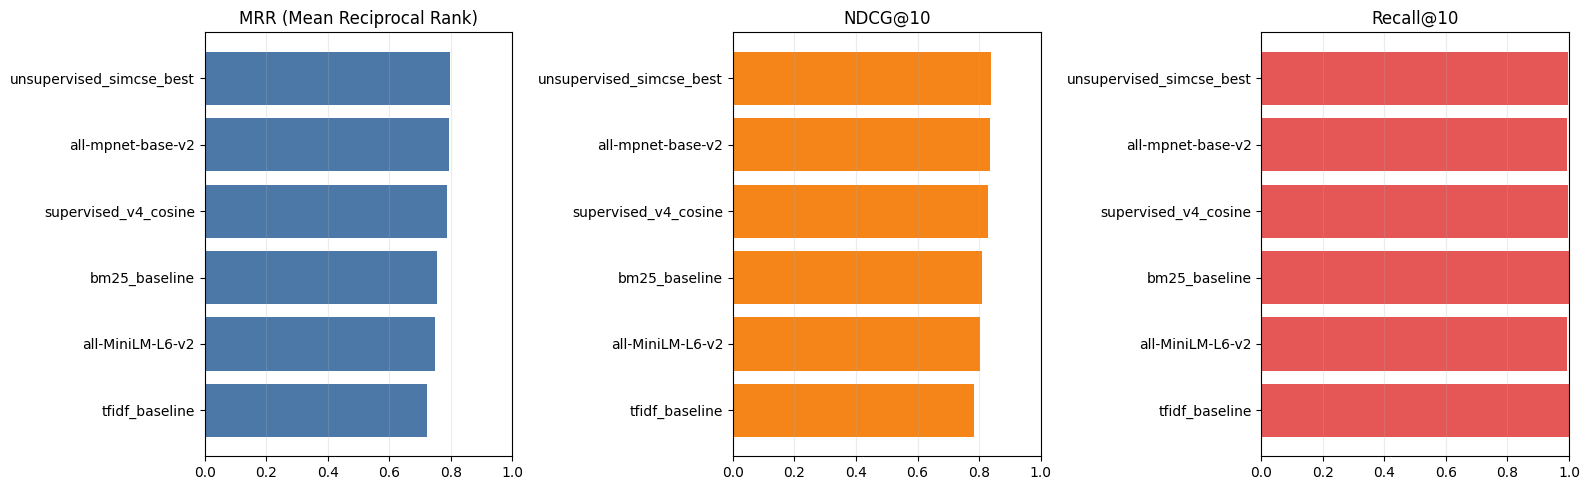

In [35]:
# R2_Retrieval_Ranking_Metrics
# Purpose: Compute NDCG@k, MRR, and Recall@k for all evaluated models using query-grouped candidate sets.

eval_labels = DATA_BUNDLE["evaluation_data"]["labels"]
eval_texts1 = DATA_BUNDLE["evaluation_data"]["texts1"]
eval_texts2 = DATA_BUNDLE["evaluation_data"]["texts2"]
batch_size = CONFIG["eval"]["batch_size"]
k_values = [5, 10, 20, 50]

ranking_bundle = build_retrieval_eval_groups(
    eval_texts1,
    eval_texts2,
    eval_labels,
    DATA_BUNDLE["corpus_texts"],
    min_candidates=int(CONFIG["eval"].get("retrieval_min_candidates", 6)),
    hard_negatives_per_query=int(CONFIG["eval"].get("retrieval_hard_negatives", 4)),
    random_negatives_per_query=int(CONFIG["eval"].get("retrieval_random_negatives", 2)),
    seed=CONFIG["seed"],
)

RANKING_EVAL_HEALTH = {
    "n_queries": ranking_bundle["n_queries"],
    "queries_with_positive": ranking_bundle["queries_with_positive"],
    "mean_group_size": ranking_bundle["mean_group_size"],
    "max_group_size": ranking_bundle["max_group_size"],
    "single_candidate_query_ratio": ranking_bundle["single_candidate_query_ratio"],
    "n_pairs_for_ranking": int(ranking_bundle["labels"].shape[0]),
}

print("ranking_eval_health:", RANKING_EVAL_HEALTH)
if RANKING_EVAL_HEALTH["single_candidate_query_ratio"] > 0.5:
    raise RuntimeError(
        f"Ranking evaluation invalid: single_candidate_query_ratio={RANKING_EVAL_HEALTH['single_candidate_query_ratio']:.3f} > 0.5"
    )

rank_texts1 = ranking_bundle["texts1"]
rank_texts2 = ranking_bundle["texts2"]
rank_labels = ranking_bundle["labels"]
rank_query_ids = ranking_bundle["query_ids"]

retrieval_rows = []

for model_name, payload in MODEL_METRICS.items():
    method_type = payload["method_type"]

    if method_type == "lexical_baseline":
        if model_name == "tfidf_baseline":
            scores = tfidf_cosine_scores(rank_texts1, rank_texts2)
        elif model_name == "bm25_baseline":
            scores = bm25_scores(rank_texts1, rank_texts2)
        else:
            continue
    else:
        model = LOADED_MODELS.get(model_name)
        if model is None:
            try:
                spec = build_reload_spec(model_name, payload)
                model = pipeline.load_sentence_model(spec, DEVICE)
            except Exception as exc:
                print(f"  Skipping {model_name} for retrieval metrics: {exc}")
                continue
        scores = cosine_scores(model, rank_texts1, rank_texts2, batch_size)
        if model_name in LOADED_MODELS:
            del LOADED_MODELS[model_name]
        del model
        pipeline.cleanup_memory(DEVICE)

    ranking = retrieval_ranking_metrics(
        labels=rank_labels,
        scores=scores,
        query_ids=rank_query_ids,
        k_values=k_values,
    )
    row = {"model_name": model_name, "method_type": method_type}
    row.update(ranking)
    retrieval_rows.append(row)
    print(
        f"{model_name}: MRR={ranking['mrr']:.4f}, "
        f"NDCG@5={ranking['ndcg@5']:.4f}, NDCG@10={ranking['ndcg@10']:.4f}, "
        f"queries={ranking['n_queries']}, mean_group={ranking['mean_group_size']:.2f}"
    )

RETRIEVAL_RANKING_DF = pd.DataFrame(retrieval_rows)
RETRIEVAL_RANKING_DF = RETRIEVAL_RANKING_DF.sort_values("ndcg@10", ascending=False).reset_index(drop=True)

print("\n=== Retrieval Ranking Metrics (sorted by NDCG@10) ===")
display(RETRIEVAL_RANKING_DF)

if not RETRIEVAL_RANKING_DF.empty:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    plot_df = RETRIEVAL_RANKING_DF.sort_values("ndcg@10", ascending=True)

    axes[0].barh(plot_df["model_name"], plot_df["mrr"], color="#4C78A8")
    axes[0].set_title("MRR (Mean Reciprocal Rank)")
    axes[0].set_xlim(0, 1)
    axes[0].grid(axis="x", alpha=0.25)

    axes[1].barh(plot_df["model_name"], plot_df["ndcg@10"], color="#F58518")
    axes[1].set_title("NDCG@10")
    axes[1].set_xlim(0, 1)
    axes[1].grid(axis="x", alpha=0.25)

    axes[2].barh(plot_df["model_name"], plot_df["recall@10"], color="#E45756")
    axes[2].set_title("Recall@10")
    axes[2].set_xlim(0, 1)
    axes[2].grid(axis="x", alpha=0.25)

    plt.tight_layout()
    plt.show()


In [ ]:
# R3_Paired_Bootstrap_Significance_Testing
# Purpose: Test whether differences between top models are statistically significant.

eval_labels = DATA_BUNDLE["evaluation_data"]["labels"]
eval_texts1 = DATA_BUNDLE["evaluation_data"]["texts1"]
eval_texts2 = DATA_BUNDLE["evaluation_data"]["texts2"]
batch_size = CONFIG["eval"]["batch_size"]

# Identify top models to compare (exclude lexical baselines)
embedding_models = {k: v for k, v in MODEL_METRICS.items() if v["method_type"] != "lexical_baseline"}
if len(embedding_models) < 2:
    print("Need at least 2 embedding models for significance testing.")
else:
    # Sort by eval spearman
    sorted_models = sorted(
        embedding_models.items(),
        key=lambda x: x[1]["metrics"]["evaluation"].get("spearman", 0),
        reverse=True,
    )

    # Key comparisons: top model vs each other model
    top_name = sorted_models[0][0]
    print(f"Reference model (best Spearman): {top_name}")
    print(f"Computing pairwise scores for significance testing...\n")

    # Cache scores for each model
    model_scores_cache = {}
    for model_name, payload in sorted_models[:6]:  # Top 6 models
        model = LOADED_MODELS.get(model_name)
        if model is None:
            try:
                spec = build_reload_spec(model_name, payload)
                model = pipeline.load_sentence_model(spec, DEVICE)
            except Exception as exc:
                print(f"  Skipping {model_name}: {exc}")
                continue
        model_scores_cache[model_name] = cosine_scores(model, eval_texts1, eval_texts2, batch_size)
        if model_name in LOADED_MODELS:
            del LOADED_MODELS[model_name]
        del model
        pipeline.cleanup_memory(DEVICE)

    sig_rows = []
    if top_name in model_scores_cache:
        top_scores = model_scores_cache[top_name]
        for model_name, payload in sorted_models[1:6]:
            if model_name not in model_scores_cache:
                continue
            other_scores = model_scores_cache[model_name]

            # Test Spearman difference
            spearman_test = paired_bootstrap_test(
                eval_labels, top_scores, other_scores,
                metric_fn=lambda y, s: spearmanr(s, y)[0],
                n_bootstrap=5000, seed=CONFIG["seed"],
            )
            # Test ROC-AUC difference
            roc_test = paired_bootstrap_test(
                eval_labels, top_scores, other_scores,
                metric_fn=roc_auc_score,
                n_bootstrap=5000, seed=CONFIG["seed"],
            )

            sig_rows.append({
                "comparison": f"{top_name} vs {model_name}",
                "spearman_delta": spearman_test["observed_delta"],
                "spearman_p": spearman_test["p_value"],
                "spearman_sig": spearman_test["significant_at_005"],
                "spearman_ci": f"[{spearman_test['ci_95_low']:.4f}, {spearman_test['ci_95_high']:.4f}]",
                "roc_auc_delta": roc_test["observed_delta"],
                "roc_auc_p": roc_test["p_value"],
                "roc_auc_sig": roc_test["significant_at_005"],
                "roc_auc_ci": f"[{roc_test['ci_95_low']:.4f}, {roc_test['ci_95_high']:.4f}]",
            })

            sig_flag = "*" if spearman_test["significant_at_005"] else "ns"
            print(f"{top_name} vs {model_name}: delta_spearman={spearman_test['observed_delta']:+.4f} (p={spearman_test['p_value']:.4f} {sig_flag})")

    SIGNIFICANCE_DF = pd.DataFrame(sig_rows)
    if not SIGNIFICANCE_DF.empty:
        print("\n=== Pairwise Significance Tests (vs best model) ===")
        display(SIGNIFICANCE_DF)

        n_sig = SIGNIFICANCE_DF["spearman_sig"].sum()
        n_total = len(SIGNIFICANCE_DF)
        print(f"\n{n_sig}/{n_total} comparisons show statistically significant Spearman differences (p < 0.05)")
        if n_sig == 0:
            print(">> None of the top model differences are statistically significant.")
            print(">> The models are effectively tied on this evaluation set.")


Reference model (best Spearman): all-mpnet-base-v2
Computing pairwise scores for significance testing...



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
# R4_Error_Analysis
# Purpose: Identify and analyze prediction errors (false positives, false negatives, borderline cases).

eval_labels = DATA_BUNDLE["evaluation_data"]["labels"]
eval_texts1 = DATA_BUNDLE["evaluation_data"]["texts1"]
eval_texts2 = DATA_BUNDLE["evaluation_data"]["texts2"]
batch_size = CONFIG["eval"]["batch_size"]

# Run error analysis on the top-performing model and the supervised V4
models_to_analyze = []
if "all-mpnet-base-v2" in MODEL_METRICS:
    models_to_analyze.append("all-mpnet-base-v2")
if "supervised_v4_cosine" in MODEL_METRICS:
    models_to_analyze.append("supervised_v4_cosine")
if "unsupervised_simcse_best" in MODEL_METRICS:
    models_to_analyze.append("unsupervised_simcse_best")

ERROR_ANALYSES = {}

for model_name in models_to_analyze:
    payload = MODEL_METRICS[model_name]
    threshold = payload["metrics"]["evaluation"]["threshold"]

    # Load model and compute scores
    model = LOADED_MODELS.get(model_name)
    if model is None:
        try:
            spec = build_reload_spec(model_name, payload)
            model = pipeline.load_sentence_model(spec, DEVICE)
        except Exception as exc:
            print(f"  Skipping {model_name}: {exc}")
            continue

    scores = cosine_scores(model, eval_texts1, eval_texts2, batch_size)
    analysis = error_analysis(eval_labels, scores, eval_texts1, eval_texts2, threshold)
    ERROR_ANALYSES[model_name] = analysis

    if model_name in LOADED_MODELS:
        del LOADED_MODELS[model_name]
    del model
    pipeline.cleanup_memory(DEVICE)

    print(f"\n{'='*60}")
    print(f"Error Analysis: {model_name} (threshold={threshold:.3f})")
    print(f"{'='*60}")
    print(f"Total pairs: {analysis['total_pairs']}")
    print(f"False Positives: {analysis['total_fp']} (rate: {analysis['fp_rate']:.3f})")
    print(f"False Negatives: {analysis['total_fn']} (rate: {analysis['fn_rate']:.3f})")
    print(f"Borderline cases (within 0.1 of threshold): {analysis['total_borderline']}")

    if analysis["top_false_positives"]:
        print(f"\nTop False Positives (model says similar, actually dissimilar):")
        fp_df = pd.DataFrame(analysis["top_false_positives"][:10])
        display(fp_df[["score", "text1_preview", "text2_preview"]])

    if analysis["top_false_negatives"]:
        print(f"\nTop False Negatives (model says dissimilar, actually similar):")
        fn_df = pd.DataFrame(analysis["top_false_negatives"][:10])
        display(fn_df[["score", "text1_preview", "text2_preview"]])

# Cross-model error comparison
if len(ERROR_ANALYSES) >= 2:
    print("\n\n=== Cross-Model Error Summary ===")
    err_summary = pd.DataFrame([
        {
            "Model": name,
            "False Positives": a["total_fp"],
            "False Negatives": a["total_fn"],
            "FP Rate": f"{a['fp_rate']:.3f}",
            "FN Rate": f"{a['fn_rate']:.3f}",
            "Borderline": a["total_borderline"],
        }
        for name, a in ERROR_ANALYSES.items()
    ])
    display(err_summary)


In [ ]:
# R5_Computational_Cost_Benchmarks
# Purpose: Measure inference latency, throughput, and GPU memory for each model to inform production decisions.

# Use a representative sample of texts for benchmarking
BENCHMARK_SAMPLE_SIZE = 200
sample_texts = DATA_BUNDLE["corpus_texts"][:BENCHMARK_SAMPLE_SIZE]
batch_size = CONFIG["eval"]["batch_size"]

# Only benchmark embedding models (not lexical baselines)
benchmark_models = [
    (name, payload) for name, payload in MODEL_METRICS.items()
    if payload["method_type"] != "lexical_baseline"
]

benchmark_rows = []
for model_name, payload in benchmark_models:
    print(f"Benchmarking {model_name}...")
    try:
        spec = build_reload_spec(model_name, payload)
        model = pipeline.load_sentence_model(spec, DEVICE)
        bench = benchmark_model_inference(model, sample_texts, batch_size=batch_size)
        bench["model_name"] = model_name
        bench["method_type"] = payload["method_type"]
        benchmark_rows.append(bench)

        print(f"  {model_name}: {bench['per_text_ms']:.2f} ms/text, "
              f"{bench['throughput_texts_per_sec']:.0f} texts/sec, "
              f"{bench['gpu_peak_memory_mb']:.0f} MB GPU")

        del model
        pipeline.cleanup_memory(DEVICE)
    except Exception as exc:
        print(f"  Skipping {model_name}: {exc}")
        pipeline.cleanup_memory(DEVICE)

BENCHMARK_DF = pd.DataFrame(benchmark_rows)
if not BENCHMARK_DF.empty:
    BENCHMARK_DF = BENCHMARK_DF.sort_values("per_text_ms").reset_index(drop=True)
    print("\n=== Inference Benchmarks (sorted by latency) ===")
    display(BENCHMARK_DF[["model_name", "method_type", "per_text_ms", "throughput_texts_per_sec", "gpu_peak_memory_mb", "total_parameters"]])

    # Add spearman for cost-effectiveness analysis
    for i, row in BENCHMARK_DF.iterrows():
        mn = row["model_name"]
        if mn in MODEL_METRICS:
            BENCHMARK_DF.loc[i, "eval_spearman"] = MODEL_METRICS[mn]["metrics"]["evaluation"].get("spearman", float("nan"))

    # Cost-effectiveness plot: Spearman vs Latency
    if "eval_spearman" in BENCHMARK_DF.columns:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.scatter(
            BENCHMARK_DF["per_text_ms"],
            BENCHMARK_DF["eval_spearman"],
            s=BENCHMARK_DF["total_parameters"] / 1e6,  # Size by param count (in millions)
            alpha=0.7,
            edgecolors="black",
            linewidths=0.5,
        )
        for _, row in BENCHMARK_DF.iterrows():
            ax.annotate(row["model_name"], (row["per_text_ms"], row["eval_spearman"]),
                       textcoords="offset points", xytext=(5, 5), fontsize=8)
        ax.set_xlabel("Latency (ms per text)")
        ax.set_ylabel("Eval Spearman")
        ax.set_title("Cost-Effectiveness: Quality vs Speed (bubble size = param count)")
        ax.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()


In [ ]:
# R6_Train_Eval_Distribution_Comparison
# Purpose: Investigate supervised model underperformance by comparing training vs evaluation data distributions.

from pathlib import Path as _P
import glob as _glob

# Find curriculum training pair files
curriculum_dir = PROJECT_ROOT / "data_new"
train_pair_paths = sorted(curriculum_dir.glob("curriculum_training_pairs_*.json"))

if not train_pair_paths:
    # Fallback: look for any training pair files
    train_pair_paths = sorted(curriculum_dir.glob("*train*pairs*.json"))
    if not train_pair_paths:
        train_pair_paths = sorted((PROJECT_ROOT / "data").glob("*train*pairs*.json"))

print(f"Found {len(train_pair_paths)} training pair files:")
for p in train_pair_paths:
    print(f"  {p.name}")

if train_pair_paths:
    dist_comparison = compare_distributions(
        train_pair_paths,
        DATA_BUNDLE["evaluation_data"]["texts1"],
        DATA_BUNDLE["evaluation_data"]["texts2"],
        DATA_BUNDLE["evaluation_data"]["labels"],
    )

    if "error" not in dist_comparison:
        print(f"\n=== Distribution Comparison ===")
        print(f"\nTraining pairs: {dist_comparison['train_pair_count']}")
        print(f"Evaluation pairs: {dist_comparison['eval_pair_count']}")

        print(f"\n--- Label Distribution ---")
        print(f"  Train: mean={dist_comparison['train_label_distribution']['mean']:.3f}, "
              f"std={dist_comparison['train_label_distribution']['std']:.3f}, "
              f"pos_ratio={dist_comparison['train_label_distribution']['positive_ratio']:.3f}")
        print(f"  Eval:  mean={dist_comparison['eval_label_distribution']['mean']:.3f}, "
              f"std={dist_comparison['eval_label_distribution']['std']:.3f}, "
              f"pos_ratio={dist_comparison['eval_label_distribution']['positive_ratio']:.3f}")

        print(f"\n--- Text Length (words) ---")
        print(f"  Train: mean={dist_comparison['train_text_length']['mean']:.1f}, "
              f"median={dist_comparison['train_text_length']['median']:.1f}")
        print(f"  Eval:  mean={dist_comparison['eval_text_length']['mean']:.1f}, "
              f"median={dist_comparison['eval_text_length']['median']:.1f}")

        print(f"\n--- Vocabulary Overlap ---")
        print(f"  Overlap ratio: {dist_comparison['vocabulary_overlap_ratio']:.3f}")

        if dist_comparison['vocabulary_overlap_ratio'] < 0.5:
            print("  >> WARNING: Low vocabulary overlap suggests domain drift between train and eval data!")

        label_diff = abs(
            dist_comparison['train_label_distribution']['positive_ratio'] -
            dist_comparison['eval_label_distribution']['positive_ratio']
        )
        if label_diff > 0.15:
            print(f"  >> WARNING: Label distribution mismatch ({label_diff:.2f} difference in positive ratio)")
            print("  >> This could explain supervised model underperformance.")

        print(f"\n--- Vocabulary Unique to Training (sample) ---")
        print(f"  {', '.join(dist_comparison['train_only_top_terms'][:15])}")
        print(f"\n--- Vocabulary Unique to Evaluation (sample) ---")
        print(f"  {', '.join(dist_comparison['eval_only_top_terms'][:15])}")

        # Visualization
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

        # Label distribution comparison
        train_label = dist_comparison["train_label_distribution"]
        eval_label = dist_comparison["eval_label_distribution"]
        x_pos = [0, 1]
        axes[0].bar(x_pos, [train_label["positive_ratio"], eval_label["positive_ratio"]],
                    color=["#4C78A8", "#F58518"], tick_label=["Train", "Eval"])
        axes[0].set_title("Positive Label Ratio")
        axes[0].set_ylim(0, 1)
        axes[0].grid(axis="y", alpha=0.25)

        # Text length comparison
        axes[1].bar(x_pos, [dist_comparison["train_text_length"]["mean"], dist_comparison["eval_text_length"]["mean"]],
                    color=["#4C78A8", "#F58518"], tick_label=["Train", "Eval"])
        axes[1].set_title("Mean Text Length (words)")
        axes[1].grid(axis="y", alpha=0.25)

        # Vocabulary overlap Venn-style
        overlap = dist_comparison["vocabulary_overlap_ratio"]
        axes[2].bar([0, 1, 2], [1 - overlap, overlap, 1 - overlap],
                    color=["#4C78A8", "#59A14F", "#F58518"],
                    tick_label=["Train Only", "Shared", "Eval Only"])
        axes[2].set_title("Vocabulary Overlap")
        axes[2].set_ylim(0, 1)
        axes[2].grid(axis="y", alpha=0.25)

        plt.tight_layout()
        plt.show()
    else:
        print(f"Error: {dist_comparison['error']}")
else:
    print("No training pair files found. Skipping distribution comparison.")

In [ ]:
# R7_Save_Extended_Analysis_Artifacts
# Purpose: Persist all recommendation analysis results to the output directory.

extended_payload = {}

if "tfidf_baseline" in MODEL_METRICS:
    extended_payload["lexical_baselines"] = {
        "tfidf": MODEL_METRICS["tfidf_baseline"]["metrics"]["evaluation"],
        "bm25": MODEL_METRICS["bm25_baseline"]["metrics"]["evaluation"],
    }
    if embedding_lift:
        extended_payload["embedding_value_add"] = embedding_lift

if "RETRIEVAL_RANKING_DF" in globals() and not RETRIEVAL_RANKING_DF.empty:
    extended_payload["retrieval_ranking"] = RETRIEVAL_RANKING_DF.to_dict(orient="records")

if "RANKING_EVAL_HEALTH" in globals() and RANKING_EVAL_HEALTH:
    extended_payload["ranking_eval_health"] = RANKING_EVAL_HEALTH

if "SIGNIFICANCE_DF" in globals() and not SIGNIFICANCE_DF.empty:
    extended_payload["significance_tests"] = SIGNIFICANCE_DF.to_dict(orient="records")

if "ERROR_ANALYSES" in globals() and ERROR_ANALYSES:
    extended_payload["error_analysis"] = {
        name: {
            "total_fp": a["total_fp"],
            "total_fn": a["total_fn"],
            "fp_rate": a["fp_rate"],
            "fn_rate": a["fn_rate"],
            "total_borderline": a["total_borderline"],
        }
        for name, a in ERROR_ANALYSES.items()
    }

if "BENCHMARK_DF" in globals() and not BENCHMARK_DF.empty:
    extended_payload["benchmarks"] = BENCHMARK_DF.to_dict(orient="records")

if "dist_comparison" in globals() and "error" not in dist_comparison:
    extended_payload["distribution_comparison"] = {
        k: v for k, v in dist_comparison.items() if k not in ("train_only_top_terms", "eval_only_top_terms")
    }

if "DATA_BUNDLE" in globals() and DATA_BUNDLE.get("data_profile"):
    extended_payload["data_profile"] = DATA_BUNDLE["data_profile"]

if "CLUSTER_EXTERNAL_METRICS" in globals() and CLUSTER_EXTERNAL_METRICS:
    extended_payload["cluster_external_metrics"] = CLUSTER_EXTERNAL_METRICS

extended_path = OUTPUT_ROOT / "extended_analysis.json"
extended_path.write_text(json.dumps(to_native(extended_payload), indent=2), encoding="utf-8")
print(f"Extended analysis saved to: {extended_path}")
print(f"Sections: {list(extended_payload.keys())}")


In [ ]:
# R8_Decision_Memo
# Purpose: Generate a deployment-focused decision memo from notebook evidence and save it as a markdown artifact.

winner_row = RETRIEVAL_TABLE.iloc[0] if "RETRIEVAL_TABLE" in globals() and not RETRIEVAL_TABLE.empty else None
second_row = RETRIEVAL_TABLE.iloc[1] if "RETRIEVAL_TABLE" in globals() and len(RETRIEVAL_TABLE) > 1 else None
runtime_winner = WINNER.get("winner_model") if "WINNER" in globals() else None
artifact_winner = ARTIFACT_BUNDLE["payload"].get("winner", {}).get("winner_model") if "ARTIFACT_BUNDLE" in globals() else None
sig_text = "No significance table generated."
if "SIGNIFICANCE_DF" in globals() and not SIGNIFICANCE_DF.empty:
    sig_text = f"{int(SIGNIFICANCE_DF['spearman_sig'].sum())}/{len(SIGNIFICANCE_DF)} pairwise Spearman comparisons significant at p < 0.05."

lines = [
    "# Decision Memo: Supervised vs Unsupervised Embedding Notebook",
    "",
    "## Observed performance",
]
if winner_row is not None:
    lines.append(f"- Runtime top model (cells 19/30): `{winner_row['model_name']}` with Spearman `{winner_row['spearman']:.4f}` and ROC-AUC `{winner_row['roc_auc']:.4f}`.")
if second_row is not None:
    lines.append(f"- Runner-up `{second_row['model_name']}`; Spearman gap `{(winner_row['spearman'] - second_row['spearman']):.4f}`.")
lines.extend([
    "",
    "## Trustworthiness of comparison",
    f"- Significance (cell 36): {sig_text}",
    f"- Winner consistency (cell 31): runtime=`{runtime_winner}` vs artifact=`{artifact_winner}`.",
    "- Ranking metrics are now query-group-aware and report grouping diagnostics.",
    "- Adapter-only supervised checkpoints now fail fast.",
    "",
    "## Deployment recommendation",
    "- Recommendation: **No-go** until corrected evaluation pipeline is rerun.",
    "- P0: query-group-aware ranking metrics + corrected bootstrap significance.",
    '- P0: `ARTIFACT_SOURCE_MODE="current"` for same-run diagnostics.',
    "- P1: merged supervised weights required (or explicit adapter loading support).",
    "- P1: enable HDBSCAN or exclude cluster evidence from winner rationale.",
])
memo = "\n".join(lines)
targets = [PROJECT_ROOT / "docs" / "supervised_vs_unsupervised_decision_memo.md", OUTPUT_ROOT / "decision_memo.md"]
for t in targets:
    t.parent.mkdir(parents=True, exist_ok=True)
    t.write_text(memo, encoding="utf-8")
print("Decision memo saved:", *targets, sep="\n - ")


In [ ]:
# R9_Evaluation_Sanity_Tests
# Purpose: Run lightweight sanity checks for ranking metrics, significance testing, and winner consistency.

print("Running evaluation sanity checks...")

# Ranking sanity: imperfect within-group ordering should yield MRR < 1.0.
labels_rank = np.array([1, 0, 0, 1, 0, 0], dtype=int)
scores_rank = np.array([0.9, 0.8, 0.1, 0.2, 0.7, 0.6], dtype=float)
qids = np.array(["q1", "q1", "q1", "q2", "q2", "q2"])
rank = retrieval_ranking_metrics(labels=labels_rank, scores=scores_rank, query_ids=qids, k_values=[1, 3])
assert rank["mrr"] < 1.0

# Ranking integrity: mismatched query id length must fail.
try:
    retrieval_ranking_metrics(labels=labels_rank, scores=scores_rank, query_ids=np.array(["q1"]), k_values=[1, 3])
    raise AssertionError("Expected retrieval_ranking_metrics to raise on query_ids length mismatch")
except ValueError:
    pass

# Bootstrap sanity: identical systems should not be significant.
rng = np.random.default_rng(42)
n_pos = 200
n_neg = 200
labels = np.array([1] * n_pos + [0] * n_neg, dtype=int)
identical = rng.uniform(0.0, 1.0, size=labels.shape[0])
idn = paired_bootstrap_test(labels, identical, identical, roc_auc_score, n_bootstrap=500, seed=42)
assert not idn["significant_at_005"]
assert abs(float(idn["observed_delta"])) < 1e-12

# Bootstrap sanity: clearly better scores should be significant.
best = np.concatenate([
    rng.normal(0.85, 0.05, size=n_pos),
    rng.normal(0.15, 0.05, size=n_neg),
]).clip(0.0, 1.0)
worst = np.concatenate([
    rng.normal(0.55, 0.05, size=n_pos),
    rng.normal(0.45, 0.05, size=n_neg),
]).clip(0.0, 1.0)
sep = paired_bootstrap_test(labels, best, worst, roc_auc_score, n_bootstrap=500, seed=42)
assert sep["observed_delta"] > 0.0
assert sep["ci_excludes_zero"]
assert sep["significant_at_005"]

# Ranking health gate sanity.
if "RANKING_EVAL_HEALTH" in globals() and RANKING_EVAL_HEALTH:
    assert float(RANKING_EVAL_HEALTH["single_candidate_query_ratio"]) <= 0.5

print("[pass] ranking + bootstrap synthetic sanity")
print("[info] runtime winner:", globals().get("WINNER", {}).get("winner_model"))
print("[info] artifact winner:", ARTIFACT_BUNDLE["payload"].get("winner", {}).get("winner_model"))
